In [742]:
pip install ipykernel

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [743]:
!pip install pandas numpy seaborn matplotlib scipy scikit-learn
!pip install pandas sqlalchemy pymysql


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [744]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scipy
import sklearn
from scipy.stats import f_oneway
from sqlalchemy import create_engine

In [745]:
df_data_one=pd.read_csv("files/Loan_data_1st_half.csv")

In [746]:
df_data_one.shape

(50000, 18)

In [747]:
df_data_one

,SK_ID_CURR,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,FLAG_LAST_APPL_PER_CONTRACT,NFLAG_LAST_APPL_IN_DAY,RATE_DOWN_PAYMENT,RATE_INTEREST_PRIMARY,RATE_INTEREST_PRIVILEGED,NAME_CASH_LOAN_PURPOSE,NAME_CONTRACT_STATUS,DAYS_DECISION,NAME_PAYMENT_TYPE
0,271877,Consumer loans,1730.43,17145.00,17145.00,0.00,17145.00,SATURDAY,15,Y,1,0.00,0.18,0.87,XAP,Approved,-73,Cash through the bank
1,108129,Cash loans,25188.62,607500.00,679671.00,NaN,607500.00,THURSDAY,11,Y,1,NaN,NaN,NaN,XNA,Approved,-164,XNA
2,122040,Cash loans,15060.74,112500.00,136444.50,NaN,112500.00,TUESDAY,11,Y,1,NaN,NaN,NaN,XNA,Approved,-301,Cash through the bank
3,176158,Cash loans,47041.33,450000.00,470790.00,NaN,450000.00,MONDAY,7,Y,1,NaN,NaN,NaN,XNA,Approved,-512,Cash through the bank
4,202054,Cash loans,31924.40,337500.00,404055.00,NaN,337500.00,THURSDAY,9,Y,1,NaN,NaN,NaN,Repairs,Refused,-781,Cash through the bank
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,363980,Cash loans,NaN,0.00,0.00,NaN,NaN,FRIDAY,10,Y,1,NaN,NaN,NaN,XNA,Canceled,-425,XNA
49996,231295,Cash loans,22176.40,180000.00,216418.50,NaN,180000.00,TUESDAY,12,Y,1,NaN,NaN,NaN,XNA,Approved,-700,Cash through the bank
49997,346691,Cash loans,NaN,0.00,0.00,NaN,NaN,WEDNESDAY,16,Y,1,NaN,NaN,NaN,XNA,Canceled,-13,XNA
49998,363244,Cash loans,24909.39,360000.00,409896.00,NaN,360000.00,FRIDAY,18,Y,1,NaN,NaN,NaN,XNA,Refused,-441,Cash through the bank


In [748]:
df_data_two=pd.read_json("files/Loan_data_2nd_half.json")

In [749]:
df_data_two.shape

(50000, 18)

In [750]:
df_data_two

,CODE_REJECT_REASON,NAME_TYPE_SUITE,NAME_CLIENT_TYPE,NAME_GOODS_CATEGORY,NAME_PORTFOLIO,NAME_PRODUCT_TYPE,CHANNEL_TYPE,SELLERPLACE_AREA,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,XAP,None,Repeater,Mobile,POS,XNA,Country-wide,35,Connectivity,12.00,middle,POS mobile with interest,365243.00,-42.00,300.00,-42.00,-37.00,0.00
1,XAP,Unaccompanied,Repeater,XNA,Cash,x-sell,Contact center,-1,XNA,36.00,low_action,Cash X-Sell: low,365243.00,-134.00,916.00,365243.00,365243.00,1.00
2,XAP,"Spouse, partner",Repeater,XNA,Cash,x-sell,Credit and cash offices,-1,XNA,12.00,high,Cash X-Sell: high,365243.00,-271.00,59.00,365243.00,365243.00,1.00
3,XAP,None,Repeater,XNA,Cash,x-sell,Credit and cash offices,-1,XNA,12.00,middle,Cash X-Sell: middle,365243.00,-482.00,-152.00,-182.00,-177.00,1.00
4,HC,None,Repeater,XNA,Cash,walk-in,Credit and cash offices,-1,XNA,24.00,high,Cash Street: high,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,XAP,None,Repeater,XNA,XNA,XNA,Credit and cash offices,-1,XNA,NaN,XNA,Cash,NaN,NaN,NaN,NaN,NaN,NaN
49996,XAP,None,Repeater,XNA,Cash,x-sell,Credit and cash offices,-1,XNA,12.00,middle,Cash X-Sell: middle,365243.00,-670.00,-340.00,-340.00,-338.00,1.00
49997,XAP,None,Repeater,XNA,XNA,XNA,Credit and cash offices,-1,XNA,NaN,XNA,Cash,NaN,NaN,NaN,NaN,NaN,NaN
49998,HC,None,Repeater,XNA,Cash,x-sell,Credit and cash offices,-1,XNA,36.00,high,Cash X-Sell: high,NaN,NaN,NaN,NaN,NaN,NaN


In [751]:
df=pd.concat([df_data_one,df_data_two],axis=1)

In [752]:
df

,SK_ID_CURR,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,FLAG_LAST_APPL_PER_CONTRACT,...,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,271877,Consumer loans,1730.43,17145.00,17145.00,0.00,17145.00,SATURDAY,15,Y,...,Connectivity,12.00,middle,POS mobile with interest,365243.00,-42.00,300.00,-42.00,-37.00,0.00
1,108129,Cash loans,25188.62,607500.00,679671.00,NaN,607500.00,THURSDAY,11,Y,...,XNA,36.00,low_action,Cash X-Sell: low,365243.00,-134.00,916.00,365243.00,365243.00,1.00
2,122040,Cash loans,15060.74,112500.00,136444.50,NaN,112500.00,TUESDAY,11,Y,...,XNA,12.00,high,Cash X-Sell: high,365243.00,-271.00,59.00,365243.00,365243.00,1.00
3,176158,Cash loans,47041.33,450000.00,470790.00,NaN,450000.00,MONDAY,7,Y,...,XNA,12.00,middle,Cash X-Sell: middle,365243.00,-482.00,-152.00,-182.00,-177.00,1.00
4,202054,Cash loans,31924.40,337500.00,404055.00,NaN,337500.00,THURSDAY,9,Y,...,XNA,24.00,high,Cash Street: high,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,363980,Cash loans,NaN,0.00,0.00,NaN,NaN,FRIDAY,10,Y,...,XNA,NaN,XNA,Cash,NaN,NaN,NaN,NaN,NaN,NaN
49996,231295,Cash loans,22176.40,180000.00,216418.50,NaN,180000.00,TUESDAY,12,Y,...,XNA,12.00,middle,Cash X-Sell: middle,365243.00,-670.00,-340.00,-340.00,-338.00,1.00
49997,346691,Cash loans,NaN,0.00,0.00,NaN,NaN,WEDNESDAY,16,Y,...,XNA,NaN,XNA,Cash,NaN,NaN,NaN,NaN,NaN,NaN
49998,363244,Cash loans,24909.39,360000.00,409896.00,NaN,360000.00,FRIDAY,18,Y,...,XNA,36.00,high,Cash X-Sell: high,NaN,NaN,NaN,NaN,NaN,NaN


In [753]:
df.shape

(50000, 36)

In [754]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 36 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   SK_ID_CURR                   50000 non-null  int64  
 1   NAME_CONTRACT_TYPE           50000 non-null  object 
 2   AMT_ANNUITY                  39408 non-null  float64
 3   AMT_APPLICATION              50000 non-null  float64
 4   AMT_CREDIT                   50000 non-null  float64
 5   AMT_DOWN_PAYMENT             24802 non-null  float64
 6   AMT_GOODS_PRICE              39256 non-null  float64
 7   WEEKDAY_APPR_PROCESS_START   50000 non-null  object 
 8   HOUR_APPR_PROCESS_START      50000 non-null  int64  
 9   FLAG_LAST_APPL_PER_CONTRACT  50000 non-null  object 
 10  NFLAG_LAST_APPL_IN_DAY       50000 non-null  int64  
 11  RATE_DOWN_PAYMENT            24802 non-null  float64
 12  RATE_INTEREST_PRIMARY        165 non-null    float64
 13  RATE_INTEREST_PR

In [755]:
df.dtypes

SK_ID_CURR                       int64
NAME_CONTRACT_TYPE              object
AMT_ANNUITY                    float64
AMT_APPLICATION                float64
AMT_CREDIT                     float64
AMT_DOWN_PAYMENT               float64
AMT_GOODS_PRICE                float64
WEEKDAY_APPR_PROCESS_START      object
HOUR_APPR_PROCESS_START          int64
FLAG_LAST_APPL_PER_CONTRACT     object
NFLAG_LAST_APPL_IN_DAY           int64
RATE_DOWN_PAYMENT              float64
RATE_INTEREST_PRIMARY          float64
RATE_INTEREST_PRIVILEGED       float64
NAME_CASH_LOAN_PURPOSE          object
NAME_CONTRACT_STATUS            object
DAYS_DECISION                    int64
NAME_PAYMENT_TYPE               object
CODE_REJECT_REASON              object
NAME_TYPE_SUITE                 object
NAME_CLIENT_TYPE                object
NAME_GOODS_CATEGORY             object
NAME_PORTFOLIO                  object
NAME_PRODUCT_TYPE               object
CHANNEL_TYPE                    object
SELLERPLACE_AREA         

In [756]:
df['NAME_CONTRACT_TYPE']

0        Consumer loans
1            Cash loans
2            Cash loans
3            Cash loans
4            Cash loans
              ...      
49995        Cash loans
49996        Cash loans
49997        Cash loans
49998        Cash loans
49999    Consumer loans
Name: NAME_CONTRACT_TYPE, Length: 50000, dtype: object

In [757]:
df['SK_ID_CURR']

0        271877
1        108129
2        122040
3        176158
4        202054
          ...  
49995    363980
49996    231295
49997    346691
49998    363244
49999    341727
Name: SK_ID_CURR, Length: 50000, dtype: int64

In [758]:
df.isnull().sum()

SK_ID_CURR                         0
NAME_CONTRACT_TYPE                 0
AMT_ANNUITY                    10592
AMT_APPLICATION                    0
AMT_CREDIT                         0
AMT_DOWN_PAYMENT               25198
AMT_GOODS_PRICE                10744
WEEKDAY_APPR_PROCESS_START         0
HOUR_APPR_PROCESS_START            0
FLAG_LAST_APPL_PER_CONTRACT        0
NFLAG_LAST_APPL_IN_DAY             0
RATE_DOWN_PAYMENT              25198
RATE_INTEREST_PRIMARY          49835
RATE_INTEREST_PRIVILEGED       49835
NAME_CASH_LOAN_PURPOSE             0
NAME_CONTRACT_STATUS               0
DAYS_DECISION                      0
NAME_PAYMENT_TYPE                  0
CODE_REJECT_REASON                 0
NAME_TYPE_SUITE                24243
NAME_CLIENT_TYPE                   0
NAME_GOODS_CATEGORY                0
NAME_PORTFOLIO                     0
NAME_PRODUCT_TYPE                  0
CHANNEL_TYPE                       0
SELLERPLACE_AREA                   0
NAME_SELLER_INDUSTRY               0
C

In [759]:
df.isnull().mean()*100

SK_ID_CURR                     0.00
NAME_CONTRACT_TYPE             0.00
AMT_ANNUITY                   21.18
AMT_APPLICATION                0.00
AMT_CREDIT                     0.00
AMT_DOWN_PAYMENT              50.40
AMT_GOODS_PRICE               21.49
WEEKDAY_APPR_PROCESS_START     0.00
HOUR_APPR_PROCESS_START        0.00
FLAG_LAST_APPL_PER_CONTRACT    0.00
NFLAG_LAST_APPL_IN_DAY         0.00
RATE_DOWN_PAYMENT             50.40
RATE_INTEREST_PRIMARY         99.67
RATE_INTEREST_PRIVILEGED      99.67
NAME_CASH_LOAN_PURPOSE         0.00
NAME_CONTRACT_STATUS           0.00
DAYS_DECISION                  0.00
NAME_PAYMENT_TYPE              0.00
CODE_REJECT_REASON             0.00
NAME_TYPE_SUITE               48.49
NAME_CLIENT_TYPE               0.00
NAME_GOODS_CATEGORY            0.00
NAME_PORTFOLIO                 0.00
NAME_PRODUCT_TYPE              0.00
CHANNEL_TYPE                   0.00
SELLERPLACE_AREA               0.00
NAME_SELLER_INDUSTRY           0.00
CNT_PAYMENT                 

In [760]:
df.duplicated().sum()

np.int64(104)

In [761]:
df.duplicated(subset=['SK_ID_CURR']).sum()

np.int64(5529)

In [762]:
df.drop_duplicates(subset=['SK_ID_CURR'],inplace=True)

In [763]:
df.duplicated().sum()

np.int64(0)

In [764]:
df.describe()

,SK_ID_CURR,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,HOUR_APPR_PROCESS_START,NFLAG_LAST_APPL_IN_DAY,RATE_DOWN_PAYMENT,RATE_INTEREST_PRIMARY,RATE_INTEREST_PRIVILEGED,DAYS_DECISION,SELLERPLACE_AREA,CNT_PAYMENT,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
count,44471.00,35538.00,44471.00,44471.00,22875.00,35403.00,44471.00,44471.00,22875.00,153.00,153.00,44471.00,44471.00,35538.00,28282.00,28282.00,28282.00,28282.00,28282.00,28282.00
mean,278801.98,15289.04,166679.06,185848.38,6606.57,209397.71,12.50,1.00,0.08,0.19,0.79,-913.98,422.89,15.28,344835.50,14009.30,30958.37,76422.91,81447.00,0.32
std,102830.95,14421.96,275893.74,301835.76,17584.85,294433.20,3.34,0.06,0.11,0.09,0.09,789.51,19016.38,13.66,84008.88,72871.79,102862.18,149545.09,152957.50,0.47
min,100007.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.06,0.42,-2922.00,-1.00,0.00,-2908.00,-2891.00,-2800.00,-2850.00,-2844.00,0.00
25%,189715.50,6077.01,23800.50,27400.50,0.00,48829.50,10.00,1.00,0.00,0.16,0.72,-1365.00,-1.00,6.00,365243.00,-1641.00,-1271.00,-1339.00,-1296.75,0.00
50%,278978.00,10737.83,72000.00,79672.50,1575.00,102055.50,12.00,1.00,0.05,0.19,0.84,-618.00,16.00,12.00,365243.00,-823.00,-369.00,-537.00,-501.00,0.00
75%,368302.50,19275.67,179730.00,193554.00,7933.50,225000.00,15.00,1.00,0.11,0.19,0.85,-298.00,100.00,18.00,365243.00,-405.00,105.00,-72.00,-45.00,1.00
max,456254.00,234478.39,3150000.00,4104351.00,1035000.00,3150000.00,23.00,1.00,0.94,0.70,0.87,-2.00,4000000.00,60.00,365243.00,365243.00,365243.00,365243.00,365243.00,1.00


In [765]:
df.describe(include=['object'])

,NAME_CONTRACT_TYPE,WEEKDAY_APPR_PROCESS_START,FLAG_LAST_APPL_PER_CONTRACT,NAME_CASH_LOAN_PURPOSE,NAME_CONTRACT_STATUS,NAME_PAYMENT_TYPE,CODE_REJECT_REASON,NAME_TYPE_SUITE,NAME_CLIENT_TYPE,NAME_GOODS_CATEGORY,NAME_PORTFOLIO,NAME_PRODUCT_TYPE,CHANNEL_TYPE,NAME_SELLER_INDUSTRY,NAME_YIELD_GROUP,PRODUCT_COMBINATION
count,44471,44471,44471,44471,44471,44471,44471,23140,44471,44471,44471,44471,44471,44471,44471,44465
unique,4,7,2,24,4,4,9,7,4,26,5,3,8,11,5,17
top,Consumer loans,WEDNESDAY,Y,XAP,Approved,Cash through the bank,XAP,Unaccompanied,Repeater,XNA,POS,XNA,Credit and cash offices,XNA,XNA,POS household with interest
freq,21738,6807,44260,26696,29198,28943,36396,13482,31488,22996,20625,29570,17960,20299,12661,7821


In [766]:
df

,SK_ID_CURR,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,FLAG_LAST_APPL_PER_CONTRACT,...,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,271877,Consumer loans,1730.43,17145.00,17145.00,0.00,17145.00,SATURDAY,15,Y,...,Connectivity,12.00,middle,POS mobile with interest,365243.00,-42.00,300.00,-42.00,-37.00,0.00
1,108129,Cash loans,25188.62,607500.00,679671.00,NaN,607500.00,THURSDAY,11,Y,...,XNA,36.00,low_action,Cash X-Sell: low,365243.00,-134.00,916.00,365243.00,365243.00,1.00
2,122040,Cash loans,15060.74,112500.00,136444.50,NaN,112500.00,TUESDAY,11,Y,...,XNA,12.00,high,Cash X-Sell: high,365243.00,-271.00,59.00,365243.00,365243.00,1.00
3,176158,Cash loans,47041.33,450000.00,470790.00,NaN,450000.00,MONDAY,7,Y,...,XNA,12.00,middle,Cash X-Sell: middle,365243.00,-482.00,-152.00,-182.00,-177.00,1.00
4,202054,Cash loans,31924.40,337500.00,404055.00,NaN,337500.00,THURSDAY,9,Y,...,XNA,24.00,high,Cash Street: high,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49990,197725,Cash loans,32242.50,1125000.00,1125000.00,NaN,1125000.00,MONDAY,8,Y,...,XNA,60.00,low_normal,Cash Street: low,NaN,NaN,NaN,NaN,NaN,NaN
49991,250283,Cash loans,36111.60,1260000.00,1260000.00,NaN,1260000.00,WEDNESDAY,5,Y,...,XNA,60.00,low_normal,Cash Street: low,NaN,NaN,NaN,NaN,NaN,NaN
49992,432416,Consumer loans,3951.22,87612.30,87610.50,1.80,87612.30,WEDNESDAY,19,Y,...,Consumer electronics,24.00,low_action,POS household without interest,365243.00,-1140.00,-450.00,-540.00,-537.00,0.00
49995,363980,Cash loans,NaN,0.00,0.00,NaN,NaN,FRIDAY,10,Y,...,XNA,NaN,XNA,Cash,NaN,NaN,NaN,NaN,NaN,NaN


In [767]:
df.select_dtypes(exclude='object').columns

Index(['SK_ID_CURR', 'AMT_ANNUITY', 'AMT_APPLICATION', 'AMT_CREDIT',
       'AMT_DOWN_PAYMENT', 'AMT_GOODS_PRICE', 'HOUR_APPR_PROCESS_START',
       'NFLAG_LAST_APPL_IN_DAY', 'RATE_DOWN_PAYMENT', 'RATE_INTEREST_PRIMARY',
       'RATE_INTEREST_PRIVILEGED', 'DAYS_DECISION', 'SELLERPLACE_AREA',
       'CNT_PAYMENT', 'DAYS_FIRST_DRAWING', 'DAYS_FIRST_DUE',
       'DAYS_LAST_DUE_1ST_VERSION', 'DAYS_LAST_DUE', 'DAYS_TERMINATION',
       'NFLAG_INSURED_ON_APPROVAL'],
      dtype='object')

In [768]:
df.select_dtypes(exclude='object').isnull().sum()

SK_ID_CURR                       0
AMT_ANNUITY                   8933
AMT_APPLICATION                  0
AMT_CREDIT                       0
AMT_DOWN_PAYMENT             21596
AMT_GOODS_PRICE               9068
HOUR_APPR_PROCESS_START          0
NFLAG_LAST_APPL_IN_DAY           0
RATE_DOWN_PAYMENT            21596
RATE_INTEREST_PRIMARY        44318
RATE_INTEREST_PRIVILEGED     44318
DAYS_DECISION                    0
SELLERPLACE_AREA                 0
CNT_PAYMENT                   8933
DAYS_FIRST_DRAWING           16189
DAYS_FIRST_DUE               16189
DAYS_LAST_DUE_1ST_VERSION    16189
DAYS_LAST_DUE                16189
DAYS_TERMINATION             16189
NFLAG_INSURED_ON_APPROVAL    16189
dtype: int64

In [769]:
cat_columns=df.select_dtypes(include='object').columns

In [770]:
cat_columns

Index(['NAME_CONTRACT_TYPE', 'WEEKDAY_APPR_PROCESS_START',
       'FLAG_LAST_APPL_PER_CONTRACT', 'NAME_CASH_LOAN_PURPOSE',
       'NAME_CONTRACT_STATUS', 'NAME_PAYMENT_TYPE', 'CODE_REJECT_REASON',
       'NAME_TYPE_SUITE', 'NAME_CLIENT_TYPE', 'NAME_GOODS_CATEGORY',
       'NAME_PORTFOLIO', 'NAME_PRODUCT_TYPE', 'CHANNEL_TYPE',
       'NAME_SELLER_INDUSTRY', 'NAME_YIELD_GROUP', 'PRODUCT_COMBINATION'],
      dtype='object')

In [771]:
df['NAME_CONTRACT_TYPE'].value_counts(dropna=False)

NAME_CONTRACT_TYPE
Consumer loans     21738
Cash loans         17775
Revolving loans     4952
XNA                    6
Name: count, dtype: int64

In [772]:
df['NAME_CONTRACT_TYPE'].replace('XNA', np.nan, inplace=True)

C:\Users\Logaraja\AppData\Local\Temp\ipykernel_24752\3244174893.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['NAME_CONTRACT_TYPE'].replace('XNA', np.nan, inplace=True)


In [773]:
df['NAME_CONTRACT_TYPE'].isnull().mean() * 100

np.float64(0.013491938566706394)

In [774]:
df['WEEKDAY_APPR_PROCESS_START'].unique()

array(['SATURDAY', 'THURSDAY', 'TUESDAY', 'MONDAY', 'FRIDAY', 'SUNDAY',
       'WEDNESDAY'], dtype=object)

In [775]:
df['WEEKDAY_APPR_PROCESS_START'].value_counts()

WEEKDAY_APPR_PROCESS_START
WEDNESDAY    6807
FRIDAY       6712
THURSDAY     6627
TUESDAY      6607
SATURDAY     6602
MONDAY       6598
SUNDAY       4518
Name: count, dtype: int64

In [776]:
df['FLAG_LAST_APPL_PER_CONTRACT'].unique()

array(['Y', 'N'], dtype=object)

In [777]:
df['FLAG_LAST_APPL_PER_CONTRACT'].value_counts(dropna=False)

FLAG_LAST_APPL_PER_CONTRACT
Y    44260
N      211
Name: count, dtype: int64

In [778]:
df['NAME_PAYMENT_TYPE'].unique

<bound method Series.unique of 0        Cash through the bank
1                          XNA
2        Cash through the bank
3        Cash through the bank
4        Cash through the bank
                 ...          
49990    Cash through the bank
49991    Cash through the bank
49992    Cash through the bank
49995                      XNA
49998    Cash through the bank
Name: NAME_PAYMENT_TYPE, Length: 44471, dtype: object>

In [779]:
df['NAME_PAYMENT_TYPE'].value_counts(dropna=False)

NAME_PAYMENT_TYPE
Cash through the bank                        28943
XNA                                          15229
Non-cash from your account                     269
Cashless from the account of the employer       30
Name: count, dtype: int64

In [780]:
df['NAME_PAYMENT_TYPE'] = df['NAME_PAYMENT_TYPE'].replace('XNA', 'Unknown')

In [781]:
df['NAME_PAYMENT_TYPE'].value_counts(dropna=False)

NAME_PAYMENT_TYPE
Cash through the bank                        28943
Unknown                                      15229
Non-cash from your account                     269
Cashless from the account of the employer       30
Name: count, dtype: int64

In [782]:
df['NAME_CASH_LOAN_PURPOSE'].value_counts(dropna=False)

NAME_CASH_LOAN_PURPOSE
XAP                                 26696
XNA                                 16049
Repairs                               570
Other                                 371
Urgent needs                          223
Buying a used car                      71
Building a house or an annex           64
Medicine                               63
Payments on other loans                52
Everyday expenses                      46
Education                              43
Journey                                36
Furniture                              29
Buying a new car                       26
Car repairs                            24
Purchase of electronic equipment       23
Buying a home                          21
Buying a holiday home / land           20
Wedding / gift / holiday               19
Gasification / water supply            11
Business development                    8
Buying a garage                         3
Hobby                                   2
Refusal to 

In [783]:
df['NAME_CASH_LOAN_PURPOSE'] = df['NAME_CASH_LOAN_PURPOSE'].replace({
    'XAP': 'Not applicable',
    'XNA': 'Unknown'
})

In [784]:
df['NAME_CASH_LOAN_PURPOSE'].isnull().mean()*100

np.float64(0.0)

In [785]:
df['NAME_CONTRACT_STATUS'].unique()

array(['Approved', 'Refused', 'Canceled', 'Unused offer'], dtype=object)

In [786]:
df['NAME_CONTRACT_STATUS'].value_counts(dropna=False)

NAME_CONTRACT_STATUS
Approved        29198
Refused          7301
Canceled         7198
Unused offer      774
Name: count, dtype: int64

In [787]:
df['CODE_REJECT_REASON'].unique

<bound method Series.unique of 0        XAP
1        XAP
2        XAP
3        XAP
4         HC
        ... 
49990    SCO
49991     HC
49992    XAP
49995    XAP
49998     HC
Name: CODE_REJECT_REASON, Length: 44471, dtype: object>

In [788]:
df['CODE_REJECT_REASON'].value_counts(dropna=False)

CODE_REJECT_REASON
XAP       36396
HC         4215
LIMIT      1545
SCO         983
CLIENT      774
SCOFR       310
XNA         141
VERIF        94
SYSTEM       13
Name: count, dtype: int64

In [789]:
df['CODE_REJECT_REASON'] = df['CODE_REJECT_REASON'].replace({
    'XAP': 'Not applicable',
    'XNA': 'Unknown'
})

In [790]:
df['NAME_TYPE_SUITE'].value_counts(dropna=False)

NAME_TYPE_SUITE
None               21331
Unaccompanied      13482
Family              6005
Spouse, partner     1941
Children             906
Other_B              496
Other_A              244
Group of people       66
Name: count, dtype: int64

In [791]:
df['NAME_TYPE_SUITE']=df['NAME_TYPE_SUITE'].str.replace(', partner','')

In [792]:
df[cat_columns].isnull().sum()

NAME_CONTRACT_TYPE                 6
WEEKDAY_APPR_PROCESS_START         0
FLAG_LAST_APPL_PER_CONTRACT        0
NAME_CASH_LOAN_PURPOSE             0
NAME_CONTRACT_STATUS               0
NAME_PAYMENT_TYPE                  0
CODE_REJECT_REASON                 0
NAME_TYPE_SUITE                21331
NAME_CLIENT_TYPE                   0
NAME_GOODS_CATEGORY                0
NAME_PORTFOLIO                     0
NAME_PRODUCT_TYPE                  0
CHANNEL_TYPE                       0
NAME_SELLER_INDUSTRY               0
NAME_YIELD_GROUP                   0
PRODUCT_COMBINATION                6
dtype: int64

In [793]:
df[cat_columns].isnull().mean()*100

NAME_CONTRACT_TYPE             0.01
WEEKDAY_APPR_PROCESS_START     0.00
FLAG_LAST_APPL_PER_CONTRACT    0.00
NAME_CASH_LOAN_PURPOSE         0.00
NAME_CONTRACT_STATUS           0.00
NAME_PAYMENT_TYPE              0.00
CODE_REJECT_REASON             0.00
NAME_TYPE_SUITE               47.97
NAME_CLIENT_TYPE               0.00
NAME_GOODS_CATEGORY            0.00
NAME_PORTFOLIO                 0.00
NAME_PRODUCT_TYPE              0.00
CHANNEL_TYPE                   0.00
NAME_SELLER_INDUSTRY           0.00
NAME_YIELD_GROUP               0.00
PRODUCT_COMBINATION            0.01
dtype: float64

In [794]:
df['NAME_TYPE_SUITE'].value_counts(dropna=False)

NAME_TYPE_SUITE
None               21331
Unaccompanied      13482
Family              6005
Spouse              1941
Children             906
Other_B              496
Other_A              244
Group of people       66
Name: count, dtype: int64

In [795]:
categories=['Other_B','Other_A','Group of people']
df['NAME_TYPE_SUITE']=df['NAME_TYPE_SUITE'].replace(categories,'others')

In [796]:
df['NAME_TYPE_SUITE'].value_counts(dropna=False)

NAME_TYPE_SUITE
None             21331
Unaccompanied    13482
Family            6005
Spouse            1941
Children           906
others             806
Name: count, dtype: int64

In [797]:
df['NAME_TYPE_SUITE'] = df['NAME_TYPE_SUITE'].fillna('Missing')

In [798]:
df['NAME_TYPE_SUITE'].value_counts(dropna=False)

NAME_TYPE_SUITE
Missing          21331
Unaccompanied    13482
Family            6005
Spouse            1941
Children           906
others             806
Name: count, dtype: int64

In [799]:
df['NAME_CLIENT_TYPE'].unique

<bound method Series.unique of 0         Repeater
1         Repeater
2         Repeater
3         Repeater
4         Repeater
           ...    
49990     Repeater
49991    Refreshed
49992    Refreshed
49995     Repeater
49998     Repeater
Name: NAME_CLIENT_TYPE, Length: 44471, dtype: object>

In [800]:
df['NAME_CLIENT_TYPE'].value_counts(dropna=False)

NAME_CLIENT_TYPE
Repeater     31488
New           9060
Refreshed     3875
XNA             48
Name: count, dtype: int64

In [801]:
df['NAME_CLIENT_TYPE'] = df['NAME_CLIENT_TYPE'].replace({
    'XNA': 'Unknown'})

In [802]:
df['NAME_CLIENT_TYPE'].value_counts(dropna=False)

NAME_CLIENT_TYPE
Repeater     31488
New           9060
Refreshed     3875
Unknown         48
Name: count, dtype: int64

In [803]:
df['NAME_GOODS_CATEGORY'].unique

<bound method Series.unique of 0             Mobile
1                XNA
2                XNA
3                XNA
4                XNA
            ...     
49990            XNA
49991            XNA
49992    Audio/Video
49995            XNA
49998            XNA
Name: NAME_GOODS_CATEGORY, Length: 44471, dtype: object>

In [804]:
df['NAME_GOODS_CATEGORY'].value_counts(dropna=False)

NAME_GOODS_CATEGORY
XNA                         22996
Mobile                       6613
Consumer Electronics         3754
Computers                    3084
Audio/Video                  2989
Furniture                    1586
Construction Materials        777
Photo / Cinema Equipment      745
Clothing and Accessories      721
Auto Accessories              228
Jewelry                       159
Homewares                     148
Medical Supplies              134
Vehicles                       96
Sport and Leisure              84
Gardening                      77
Office Appliances              76
Other                          61
Medicine                       55
Tourism                        51
Direct Sales                   13
Fitness                         9
Education                       7
Insurance                       3
Additional Service              3
Weapon                          2
Name: count, dtype: int64

In [805]:
df['NAME_GOODS_CATEGORY'] = df['NAME_GOODS_CATEGORY'].replace({
    'XNA': 'Unknown'})

In [806]:
df['NAME_PORTFOLIO'].unique

<bound method Series.unique of 0         POS
1        Cash
2        Cash
3        Cash
4        Cash
         ... 
49990    Cash
49991    Cash
49992     POS
49995     XNA
49998    Cash
Name: NAME_PORTFOLIO, Length: 44471, dtype: object>

In [807]:
df['NAME_PORTFOLIO'].value_counts(dropna=False)

NAME_PORTFOLIO
POS      20625
Cash     11173
XNA       8933
Cards     3728
Cars        12
Name: count, dtype: int64

In [808]:
df['NAME_PORTFOLIO'] = df['NAME_PORTFOLIO'].replace({
    'XNA': 'Unknown'})

In [809]:
df['NAME_PRODUCT_TYPE'].unique

<bound method Series.unique of 0            XNA
1         x-sell
2         x-sell
3         x-sell
4        walk-in
          ...   
49990    walk-in
49991    walk-in
49992        XNA
49995        XNA
49998     x-sell
Name: NAME_PRODUCT_TYPE, Length: 44471, dtype: object>

In [810]:
df['NAME_PRODUCT_TYPE'].value_counts(dropna=False)

NAME_PRODUCT_TYPE
XNA        29570
x-sell     11048
walk-in     3853
Name: count, dtype: int64

In [811]:
df['NAME_PRODUCT_TYPE']=df['NAME_PRODUCT_TYPE'].replace({'XNA':'Unknown'})

In [812]:
df['CHANNEL_TYPE'].unique

<bound method Series.unique of 0                      Country-wide
1                    Contact center
2           Credit and cash offices
3           Credit and cash offices
4           Credit and cash offices
                    ...            
49990    Channel of corporate sales
49991    Channel of corporate sales
49992                  Country-wide
49995       Credit and cash offices
49998       Credit and cash offices
Name: CHANNEL_TYPE, Length: 44471, dtype: object>

In [813]:
df['CHANNEL_TYPE'].value_counts(dropna=False)

CHANNEL_TYPE
Credit and cash offices       17960
Country-wide                  14606
Stone                          6330
Regional / Local               3278
AP+ (Cash loan)                1445
Contact center                  598
Channel of corporate sales      240
Car dealer                       14
Name: count, dtype: int64

In [814]:
df['NAME_SELLER_INDUSTRY'].unique

<bound method Series.unique of 0                Connectivity
1                         XNA
2                         XNA
3                         XNA
4                         XNA
                 ...         
49990                     XNA
49991                     XNA
49992    Consumer electronics
49995                     XNA
49998                     XNA
Name: NAME_SELLER_INDUSTRY, Length: 44471, dtype: object>

In [815]:
df['NAME_SELLER_INDUSTRY'].value_counts(dropna=False)

NAME_SELLER_INDUSTRY
XNA                     20299
Consumer electronics    11883
Connectivity             8076
Furniture                1726
Construction              918
Clothing                  728
Industry                  567
Auto technology           157
Jewelry                    78
MLM partners               29
Tourism                    10
Name: count, dtype: int64

In [816]:
df['NAME_SELLER_INDUSTRY']=df['NAME_SELLER_INDUSTRY'].replace({'XNA':'Unknown'})

In [817]:
df['NAME_YIELD_GROUP'].value_counts(dropna=False)

NAME_YIELD_GROUP
XNA           12661
middle        10426
high           9849
low_normal     8851
low_action     2684
Name: count, dtype: int64

In [818]:
df['NAME_YIELD_GROUP']=df['NAME_YIELD_GROUP'].replace({'XNA':'Unknown'})

In [819]:
df['PRODUCT_COMBINATION'].unique

<bound method Series.unique of 0              POS mobile with interest
1                      Cash X-Sell: low
2                     Cash X-Sell: high
3                   Cash X-Sell: middle
4                     Cash Street: high
                      ...              
49990                  Cash Street: low
49991                  Cash Street: low
49992    POS household without interest
49995                              Cash
49998                 Cash X-Sell: high
Name: PRODUCT_COMBINATION, Length: 44471, dtype: object>

In [820]:
df['PRODUCT_COMBINATION'].isnull().sum()

np.int64(6)

In [821]:
df['PRODUCT_COMBINATION'].value_counts(dropna=False)

PRODUCT_COMBINATION
POS household with interest       7821
Cash                              6602
POS mobile with interest          6497
Cash X-Sell: middle               3411
Cash X-Sell: low                  3057
POS industry with interest        3030
Card Street                       2910
POS household without interest    2583
Card X-Sell                       2042
Cash Street: high                 1530
Cash X-Sell: high                 1463
Cash Street: low                   880
Cash Street: middle                832
POS mobile without interest        684
POS other with interest            682
POS industry without interest      352
POS others without interest         89
None                                 6
Name: count, dtype: int64

In [822]:
df['PRODUCT_COMBINATION']=df['PRODUCT_COMBINATION'].replace({'XNA':'Unknown'})

In [823]:
num_columns=df.select_dtypes(exclude='object').columns

In [824]:
num_columns

Index(['SK_ID_CURR', 'AMT_ANNUITY', 'AMT_APPLICATION', 'AMT_CREDIT',
       'AMT_DOWN_PAYMENT', 'AMT_GOODS_PRICE', 'HOUR_APPR_PROCESS_START',
       'NFLAG_LAST_APPL_IN_DAY', 'RATE_DOWN_PAYMENT', 'RATE_INTEREST_PRIMARY',
       'RATE_INTEREST_PRIVILEGED', 'DAYS_DECISION', 'SELLERPLACE_AREA',
       'CNT_PAYMENT', 'DAYS_FIRST_DRAWING', 'DAYS_FIRST_DUE',
       'DAYS_LAST_DUE_1ST_VERSION', 'DAYS_LAST_DUE', 'DAYS_TERMINATION',
       'NFLAG_INSURED_ON_APPROVAL'],
      dtype='object')

In [825]:
df['NFLAG_INSURED_ON_APPROVAL'].dtype

dtype('float64')

In [826]:
df.select_dtypes(exclude='object').isnull().mean()*100

SK_ID_CURR                   0.00
AMT_ANNUITY                 20.09
AMT_APPLICATION              0.00
AMT_CREDIT                   0.00
AMT_DOWN_PAYMENT            48.56
AMT_GOODS_PRICE             20.39
HOUR_APPR_PROCESS_START      0.00
NFLAG_LAST_APPL_IN_DAY       0.00
RATE_DOWN_PAYMENT           48.56
RATE_INTEREST_PRIMARY       99.66
RATE_INTEREST_PRIVILEGED    99.66
DAYS_DECISION                0.00
SELLERPLACE_AREA             0.00
CNT_PAYMENT                 20.09
DAYS_FIRST_DRAWING          36.40
DAYS_FIRST_DUE              36.40
DAYS_LAST_DUE_1ST_VERSION   36.40
DAYS_LAST_DUE               36.40
DAYS_TERMINATION            36.40
NFLAG_INSURED_ON_APPROVAL   36.40
dtype: float64

In [827]:
df['AMT_CREDIT'].describe()

count     44471.00
mean     185848.38
std      301835.76
min           0.00
25%       27400.50
50%       79672.50
75%      193554.00
max     4104351.00
Name: AMT_CREDIT, dtype: float64

In [828]:
df['AMT_ANNUITY'].describe()

count    35538.00
mean     15289.04
std      14421.96
min          0.00
25%       6077.01
50%      10737.83
75%      19275.67
max     234478.39
Name: AMT_ANNUITY, dtype: float64

In [829]:
Q1=df['AMT_ANNUITY'].quantile(0.25)

Q3=df['AMT_ANNUITY'].quantile(0.75)


In [830]:
IQR=Q3-Q1

In [831]:
IQR

np.float64(13198.6575)

In [832]:
lower_bound=Q1-1.5*IQR

In [833]:
lower_bound

np.float64(-13720.972499999998)

In [834]:
upper_bound=Q3+1.5*IQR

In [835]:
upper_bound

np.float64(39073.6575)

<Axes: >

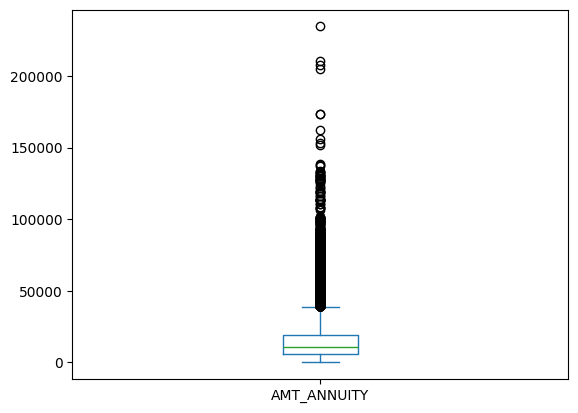

In [836]:
df['AMT_ANNUITY'].plot(kind='box')

<Axes: ylabel='Frequency'>

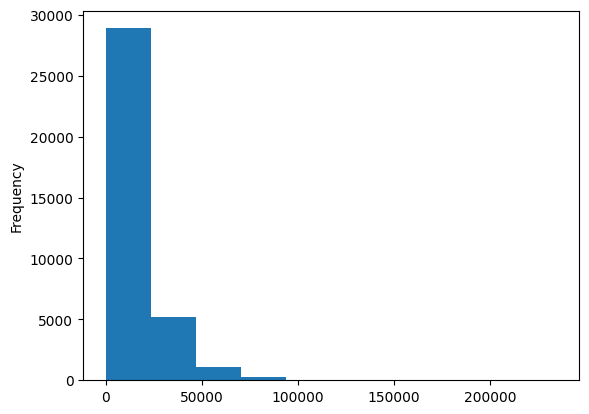

In [837]:
df['AMT_ANNUITY'].plot(kind='hist')

In [838]:
df['AMT_ANNUITY']=df['AMT_ANNUITY'].median()

In [839]:
df['AMT_ANNUITY'].isnull().sum()

np.int64(0)

In [840]:
df['AMT_DOWN_PAYMENT'].describe()

count     22875.00
mean       6606.57
std       17584.85
min           0.00
25%           0.00
50%        1575.00
75%        7933.50
max     1035000.00
Name: AMT_DOWN_PAYMENT, dtype: float64

In [841]:
df['AMT_DOWN_PAYMENT'].unique

<bound method Series.unique of 0       0.00
1        NaN
2        NaN
3        NaN
4        NaN
        ... 
49990    NaN
49991    NaN
49992   1.80
49995    NaN
49998    NaN
Name: AMT_DOWN_PAYMENT, Length: 44471, dtype: float64>

In [842]:
df['AMT_DOWN_PAYMENT']=pd.to_numeric(df['AMT_DOWN_PAYMENT'],errors='coerce')

In [843]:
pd.set_option('display.float_format', '{:.2f}'.format)
df['AMT_DOWN_PAYMENT'].describe()

count     22875.00
mean       6606.57
std       17584.85
min           0.00
25%           0.00
50%        1575.00
75%        7933.50
max     1035000.00
Name: AMT_DOWN_PAYMENT, dtype: float64

In [844]:
df['AMT_DOWN_PAYMENT']=df['AMT_DOWN_PAYMENT'].fillna(df['AMT_DOWN_PAYMENT'].median())

In [845]:
df['AMT_DOWN_PAYMENT'].isnull().sum()

np.int64(0)

In [846]:
df['AMT_GOODS_PRICE'].describe()

count     35403.00
mean     209397.71
std      294433.20
min           0.00
25%       48829.50
50%      102055.50
75%      225000.00
max     3150000.00
Name: AMT_GOODS_PRICE, dtype: float64

In [847]:
df['AMT_GOODS_PRICE']=df['AMT_GOODS_PRICE'].fillna(df['AMT_GOODS_PRICE'].median())

In [848]:
df['AMT_GOODS_PRICE'].isnull().sum()

np.int64(0)

In [849]:
df['RATE_DOWN_PAYMENT'].describe()

count   22875.00
mean        0.08
std         0.11
min         0.00
25%         0.00
50%         0.05
75%         0.11
max         0.94
Name: RATE_DOWN_PAYMENT, dtype: float64

In [850]:
df['RATE_DOWN_PAYMENT'].isnull().mean()*100

np.float64(48.561984214431874)

In [851]:
df['RATE_DOWN_PAYMENT'] = df['RATE_DOWN_PAYMENT'].fillna(
    df['RATE_DOWN_PAYMENT'].median()
)

In [852]:
df['RATE_DOWN_PAYMENT'].isnull().sum()

np.int64(0)

In [853]:
df['RATE_INTEREST_PRIMARY'].describe()

count   153.00
mean      0.19
std       0.09
min       0.06
25%       0.16
50%       0.19
75%       0.19
max       0.70
Name: RATE_INTEREST_PRIMARY, dtype: float64

In [854]:
df['RATE_INTEREST_PRIMARY'].isnull().mean()*100

np.float64(99.65595556654898)

In [855]:
df.drop(columns=['RATE_INTEREST_PRIMARY'], inplace=True)

In [856]:
df['RATE_INTEREST_PRIVILEGED'].isnull().mean()*100

np.float64(99.65595556654898)

In [857]:
df['RATE_INTEREST_PRIVILEGED'].describe()

count   153.00
mean      0.79
std       0.09
min       0.42
25%       0.72
50%       0.84
75%       0.85
max       0.87
Name: RATE_INTEREST_PRIVILEGED, dtype: float64

In [858]:
df.drop(columns=['RATE_INTEREST_PRIVILEGED'], inplace=True)

In [859]:
df['CNT_PAYMENT'].isnull().mean()*100


np.float64(20.087247869398034)

In [860]:
df['CNT_PAYMENT'].describe()

count   35538.00
mean       15.28
std        13.66
min         0.00
25%         6.00
50%        12.00
75%        18.00
max        60.00
Name: CNT_PAYMENT, dtype: float64

In [861]:
df['CNT_PAYMENT']

0       12.00
1       36.00
2       12.00
3       12.00
4       24.00
         ... 
49990   60.00
49991   60.00
49992   24.00
49995     NaN
49998   36.00
Name: CNT_PAYMENT, Length: 44471, dtype: float64

In [862]:
(df['CNT_PAYMENT'] == 0).sum()

np.int64(3728)

In [863]:
df['CNT_PAYMENT']=df['CNT_PAYMENT'].fillna(df['CNT_PAYMENT'].median())

In [864]:
df['CNT_PAYMENT'].isnull().sum()

np.int64(0)

In [865]:
df['DAYS_FIRST_DRAWING'].isnull().mean()*100

np.float64(36.403498909401634)

In [866]:
df['DAYS_FIRST_DRAWING'].describe()

count    28282.00
mean    344835.50
std      84008.88
min      -2908.00
25%     365243.00
50%     365243.00
75%     365243.00
max     365243.00
Name: DAYS_FIRST_DRAWING, dtype: float64

In [867]:
df['DAYS_FIRST_DRAWING'] = df['DAYS_FIRST_DRAWING'].fillna(
    df['DAYS_FIRST_DRAWING'].median())

In [868]:
df['DAYS_FIRST_DRAWING'].isnull().sum()

np.int64(0)

In [869]:
df['DAYS_FIRST_DUE'].isnull().mean()*100

np.float64(36.403498909401634)

In [870]:
df['DAYS_FIRST_DUE'].describe()

count    28282.00
mean     14009.30
std      72871.79
min      -2891.00
25%      -1641.00
50%       -823.00
75%       -405.00
max     365243.00
Name: DAYS_FIRST_DUE, dtype: float64

In [871]:
DAYS_FIRST_DUE_null=(19161/50000)*100
DAYS_FIRST_DUE_null

38.322

In [872]:
df['DAYS_FIRST_DUE'].skew()

np.float64(4.612166901453075)

In [873]:
df['DAYS_FIRST_DUE']=df['DAYS_FIRST_DUE'].fillna(df['DAYS_FIRST_DUE'].median())

In [874]:
df['DAYS_LAST_DUE_1ST_VERSION'].isnull().mean()*100

np.float64(36.403498909401634)

In [875]:
df['DAYS_LAST_DUE_1ST_VERSION'].describe()

count    28282.00
mean     30958.37
std     102862.18
min      -2800.00
25%      -1271.00
50%       -369.00
75%        105.00
max     365243.00
Name: DAYS_LAST_DUE_1ST_VERSION, dtype: float64

In [876]:
df['DAYS_LAST_DUE_1ST_VERSION']=df['DAYS_LAST_DUE_1ST_VERSION'].fillna(df['DAYS_LAST_DUE_1ST_VERSION'].median())

In [877]:
df['DAYS_LAST_DUE_1ST_VERSION'].isnull().sum()

np.int64(0)

In [878]:
df['DAYS_LAST_DUE'].isnull().mean()*100

np.float64(36.403498909401634)

In [879]:
df['DAYS_LAST_DUE'].describe()

count    28282.00
mean     76422.91
std     149545.09
min      -2850.00
25%      -1339.00
50%       -537.00
75%        -72.00
max     365243.00
Name: DAYS_LAST_DUE, dtype: float64

In [880]:
df['DAYS_LAST_DUE']=df['DAYS_LAST_DUE'].fillna(df['DAYS_LAST_DUE'].median())

In [881]:
df['DAYS_LAST_DUE'].isnull().sum()

np.int64(0)

In [882]:
df['DAYS_TERMINATION'].isnull().mean()*100

np.float64(36.403498909401634)

In [883]:
df['DAYS_TERMINATION'].describe()

count    28282.00
mean     81447.00
std     152957.50
min      -2844.00
25%      -1296.75
50%       -501.00
75%        -45.00
max     365243.00
Name: DAYS_TERMINATION, dtype: float64

In [884]:
df['DAYS_TERMINATION']=df['DAYS_TERMINATION'].fillna(df['DAYS_TERMINATION'].median())

In [885]:
df['DAYS_TERMINATION'].isnull().sum()

np.int64(0)

In [886]:
df['NFLAG_INSURED_ON_APPROVAL'].isnull().mean()*100

np.float64(36.403498909401634)

In [887]:
df['NFLAG_INSURED_ON_APPROVAL']

0       0.00
1       1.00
2       1.00
3       1.00
4        NaN
        ... 
49990    NaN
49991    NaN
49992   0.00
49995    NaN
49998    NaN
Name: NFLAG_INSURED_ON_APPROVAL, Length: 44471, dtype: float64

In [888]:
df['NFLAG_INSURED_ON_APPROVAL'].describe()

count   28282.00
mean        0.32
std         0.47
min         0.00
25%         0.00
50%         0.00
75%         1.00
max         1.00
Name: NFLAG_INSURED_ON_APPROVAL, dtype: float64

In [889]:
df['NFLAG_INSURED_ON_APPROVAL'].skew()

np.float64(0.7887947520719126)

In [890]:
df['NFLAG_INSURED_ON_APPROVAL'].median()

np.float64(0.0)

In [891]:
df['NFLAG_INSURED_ON_APPROVAL'].mode()

0   0.00
Name: NFLAG_INSURED_ON_APPROVAL, dtype: float64

In [892]:
df['NFLAG_INSURED_ON_APPROVAL']=df['NFLAG_INSURED_ON_APPROVAL'].fillna(df['NFLAG_INSURED_ON_APPROVAL'].mode()[0])

In [893]:
df['NFLAG_INSURED_ON_APPROVAL'].isnull().sum()

np.int64(0)

In [894]:
df.select_dtypes(exclude='object').isnull().mean()*100

SK_ID_CURR                  0.00
AMT_ANNUITY                 0.00
AMT_APPLICATION             0.00
AMT_CREDIT                  0.00
AMT_DOWN_PAYMENT            0.00
AMT_GOODS_PRICE             0.00
HOUR_APPR_PROCESS_START     0.00
NFLAG_LAST_APPL_IN_DAY      0.00
RATE_DOWN_PAYMENT           0.00
DAYS_DECISION               0.00
SELLERPLACE_AREA            0.00
CNT_PAYMENT                 0.00
DAYS_FIRST_DRAWING          0.00
DAYS_FIRST_DUE              0.00
DAYS_LAST_DUE_1ST_VERSION   0.00
DAYS_LAST_DUE               0.00
DAYS_TERMINATION            0.00
NFLAG_INSURED_ON_APPROVAL   0.00
dtype: float64

In [895]:
df.duplicated().sum()

np.int64(0)

In [896]:
df.columns

Index(['SK_ID_CURR', 'NAME_CONTRACT_TYPE', 'AMT_ANNUITY', 'AMT_APPLICATION',
       'AMT_CREDIT', 'AMT_DOWN_PAYMENT', 'AMT_GOODS_PRICE',
       'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START',
       'FLAG_LAST_APPL_PER_CONTRACT', 'NFLAG_LAST_APPL_IN_DAY',
       'RATE_DOWN_PAYMENT', 'NAME_CASH_LOAN_PURPOSE', 'NAME_CONTRACT_STATUS',
       'DAYS_DECISION', 'NAME_PAYMENT_TYPE', 'CODE_REJECT_REASON',
       'NAME_TYPE_SUITE', 'NAME_CLIENT_TYPE', 'NAME_GOODS_CATEGORY',
       'NAME_PORTFOLIO', 'NAME_PRODUCT_TYPE', 'CHANNEL_TYPE',
       'SELLERPLACE_AREA', 'NAME_SELLER_INDUSTRY', 'CNT_PAYMENT',
       'NAME_YIELD_GROUP', 'PRODUCT_COMBINATION', 'DAYS_FIRST_DRAWING',
       'DAYS_FIRST_DUE', 'DAYS_LAST_DUE_1ST_VERSION', 'DAYS_LAST_DUE',
       'DAYS_TERMINATION', 'NFLAG_INSURED_ON_APPROVAL'],
      dtype='object')

In [897]:
df.drop('SK_ID_CURR',axis=1,inplace=True)

In [898]:
df.describe()

,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,HOUR_APPR_PROCESS_START,NFLAG_LAST_APPL_IN_DAY,RATE_DOWN_PAYMENT,DAYS_DECISION,SELLERPLACE_AREA,CNT_PAYMENT,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
count,44471.00,44471.00,44471.00,44471.00,44471.00,44471.00,44471.00,44471.00,44471.00,44471.00,44471.00,44471.00,44471.00,44471.00,44471.00,44471.00,44471.00
mean,10737.83,166679.06,185848.38,4163.14,187509.76,12.50,1.00,0.07,-913.98,422.89,14.62,352264.54,8609.82,19554.11,48406.81,51615.06,0.20
std,0.00,275893.74,301835.76,12860.05,266240.47,3.34,0.06,0.08,789.51,19016.38,12.28,67710.27,58549.58,83402.85,124874.40,128193.61,0.40
min,10737.83,0.00,0.00,0.00,0.00,0.00,0.00,0.00,-2922.00,-1.00,0.00,-2908.00,-2891.00,-2800.00,-2850.00,-2844.00,0.00
25%,10737.83,23800.50,27400.50,2.70,61957.12,10.00,1.00,0.00,-1365.00,-1.00,10.00,365243.00,-1081.00,-675.00,-809.00,-772.00,0.00
50%,10737.83,72000.00,79672.50,1575.00,102055.50,12.00,1.00,0.05,-618.00,16.00,12.00,365243.00,-823.00,-369.00,-537.00,-501.00,0.00
75%,10737.83,179730.00,193554.00,2018.25,179730.00,15.00,1.00,0.08,-298.00,100.00,12.00,365243.00,-633.00,-147.00,-324.00,-290.00,0.00
max,10737.83,3150000.00,4104351.00,1035000.00,3150000.00,23.00,1.00,0.94,-2.00,4000000.00,60.00,365243.00,365243.00,365243.00,365243.00,365243.00,1.00


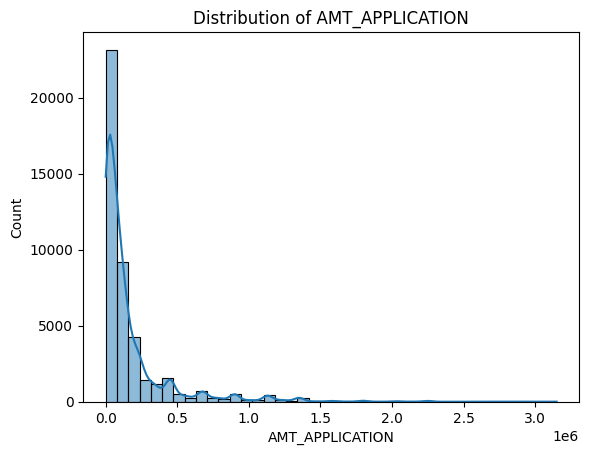

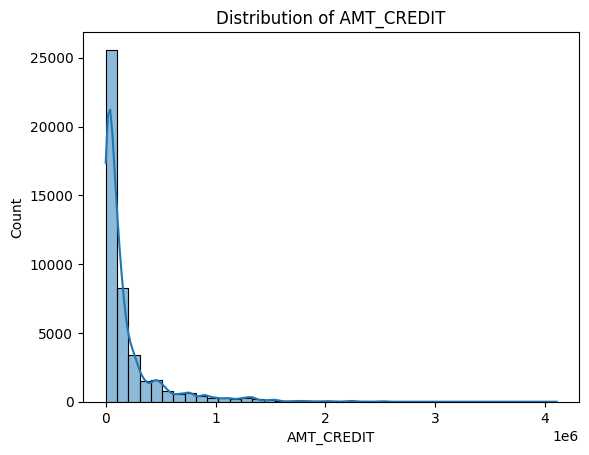

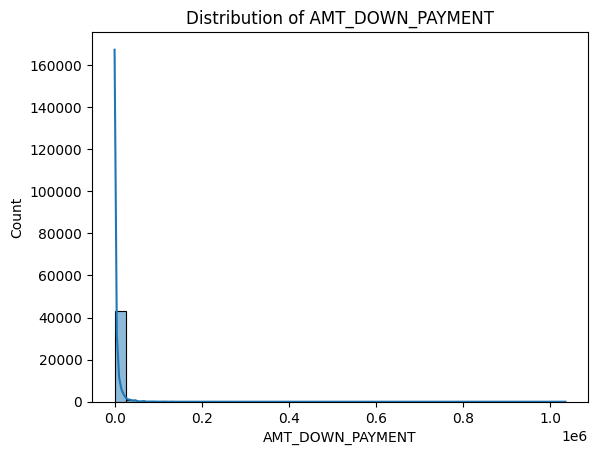

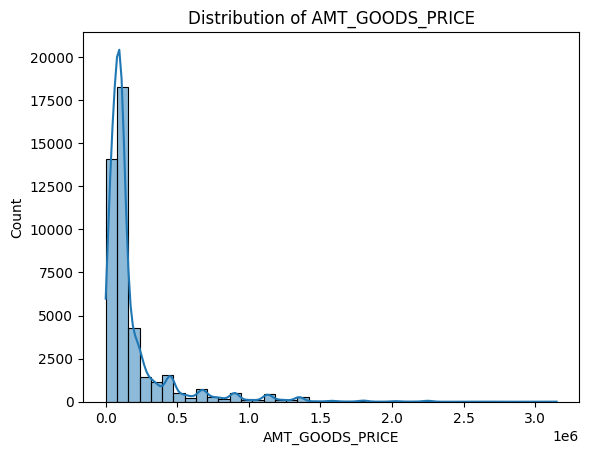

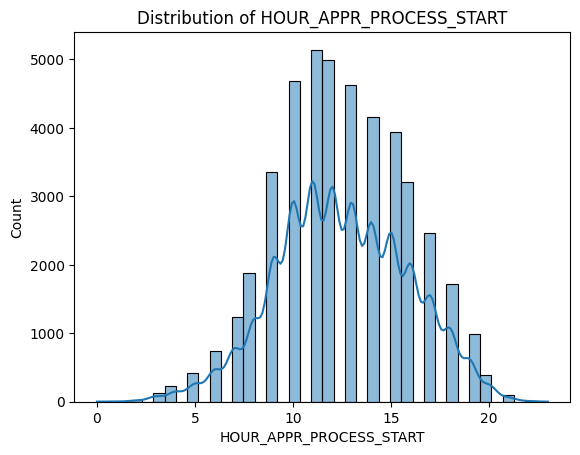

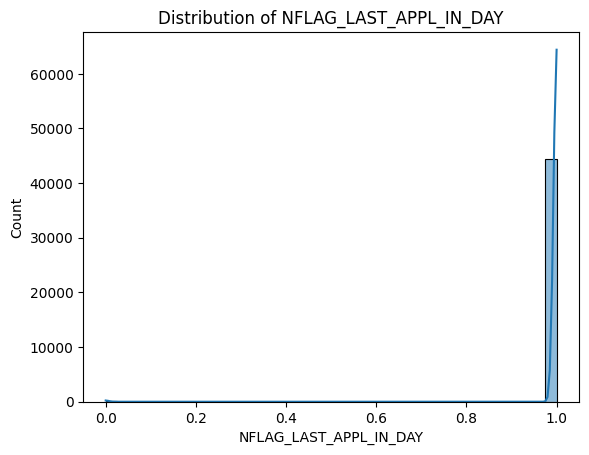

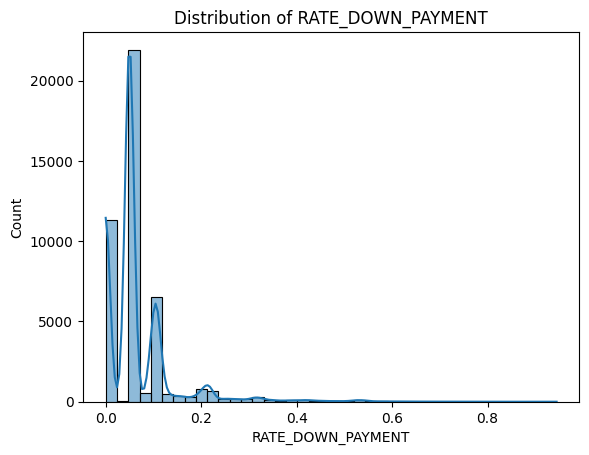

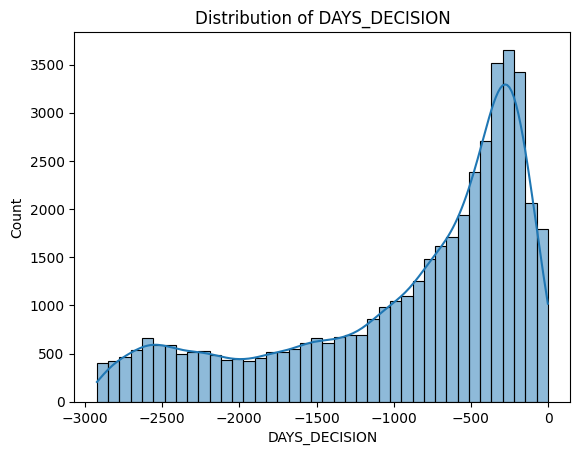

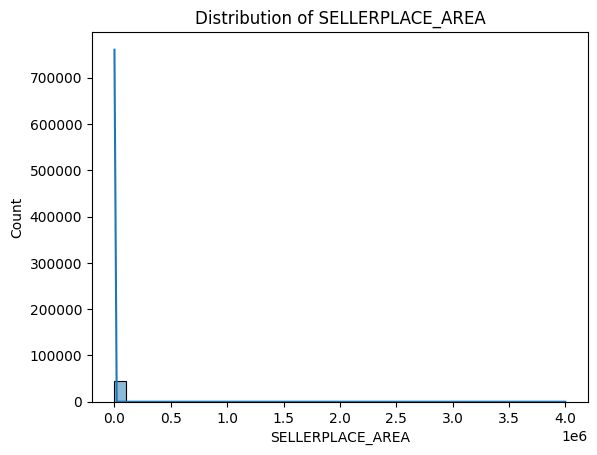

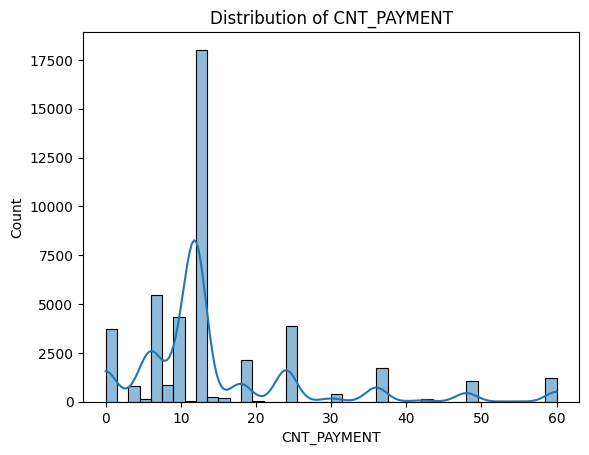

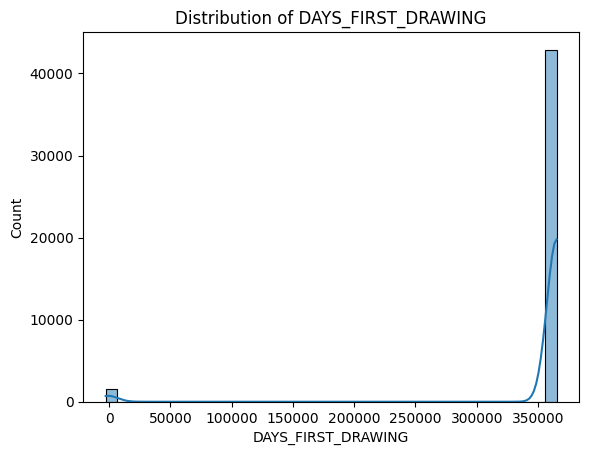

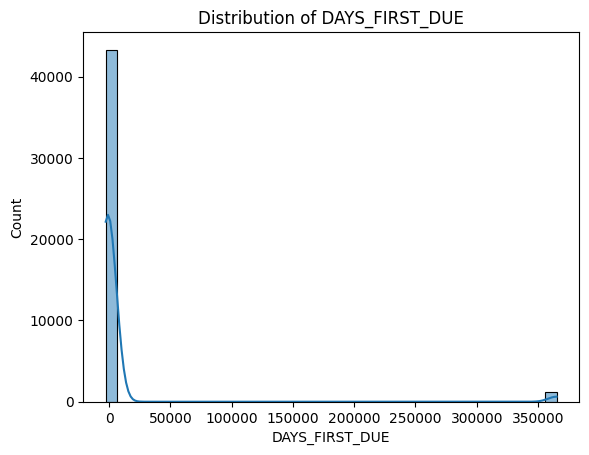

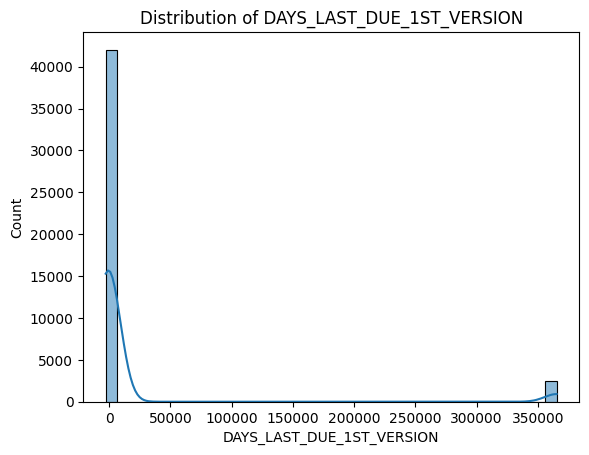

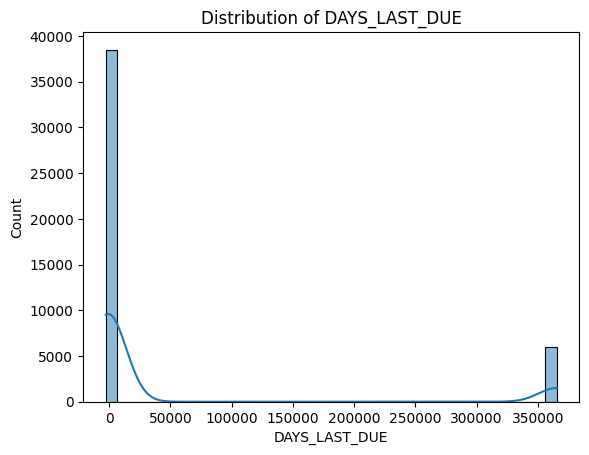

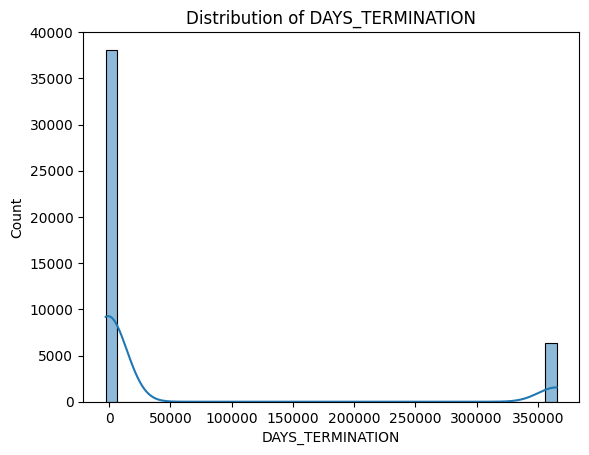

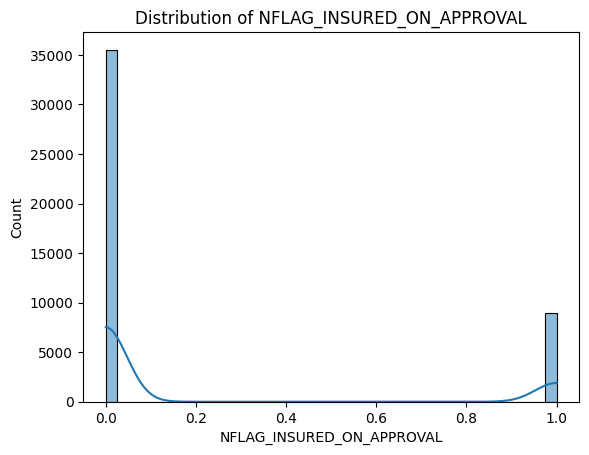

In [899]:
for column in df.select_dtypes(exclude='object').columns[1:]:
  sns.histplot(x=column, data=df,bins=40,kde=True)
  plt.title(f'Distribution of {column}')
  plt.show()

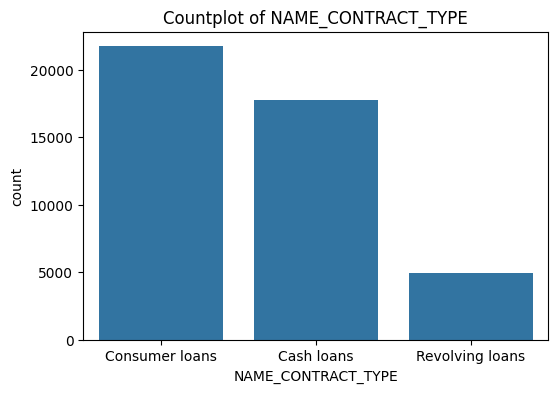

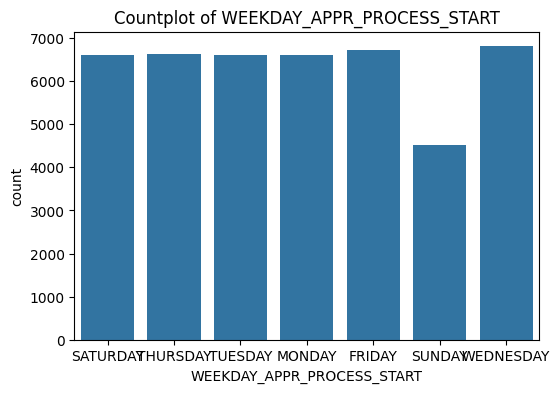

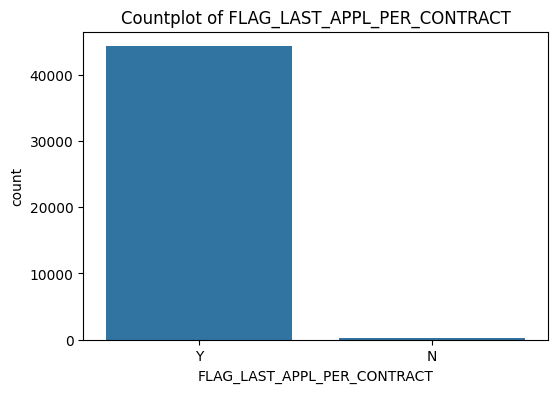

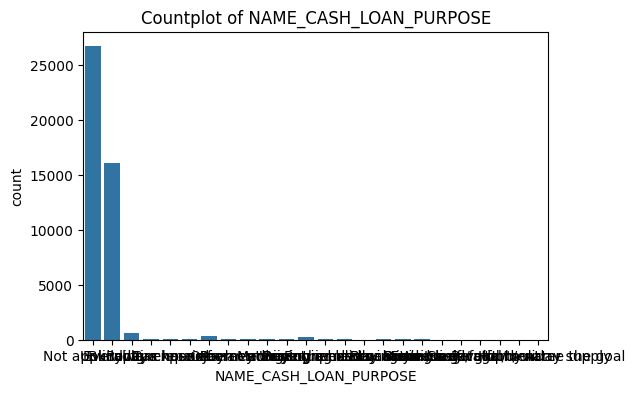

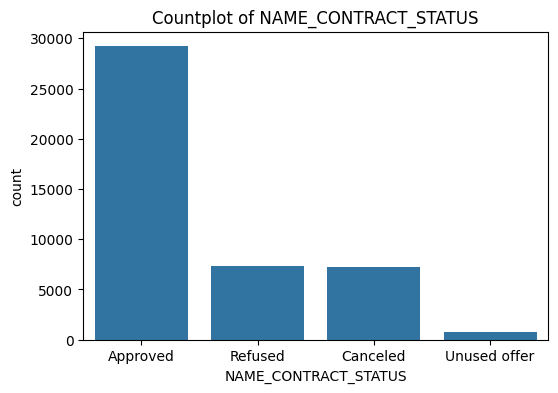

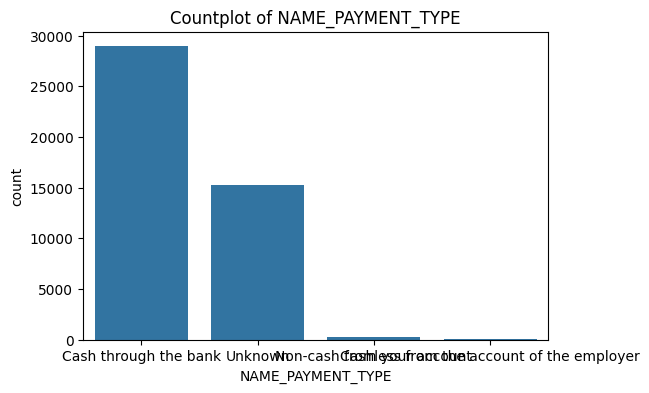

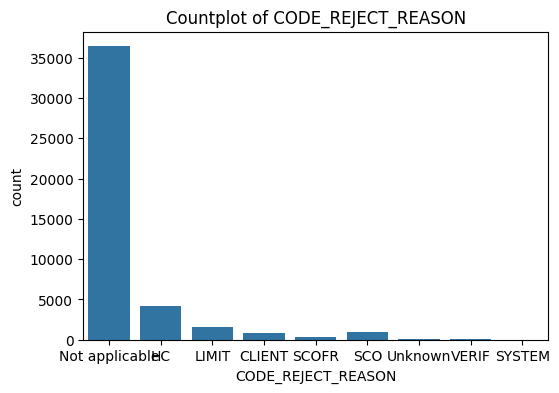

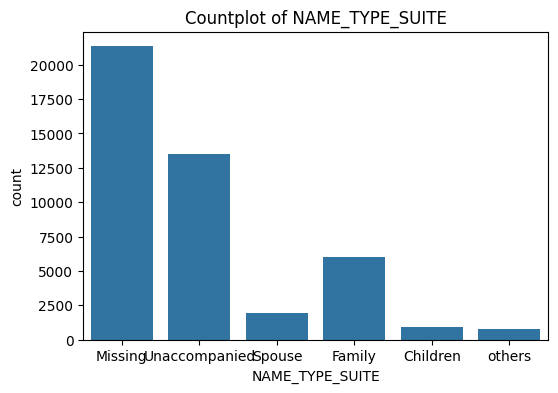

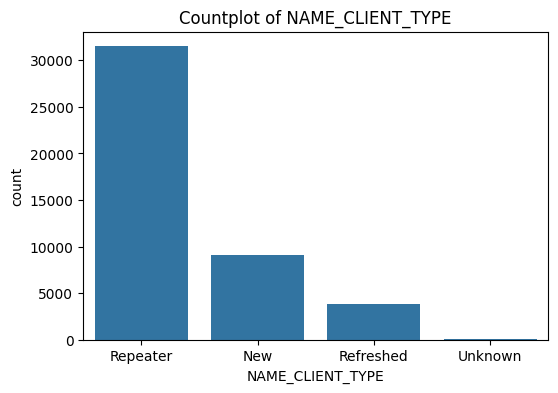

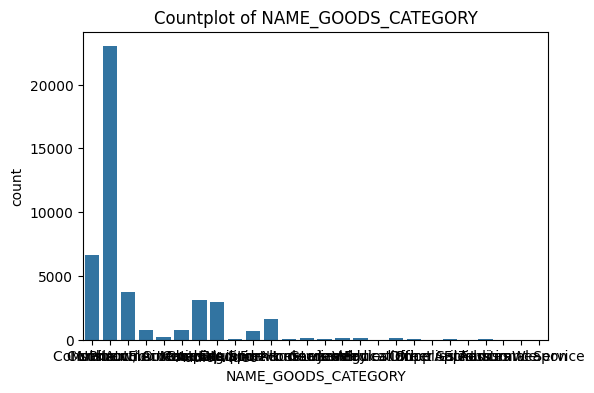

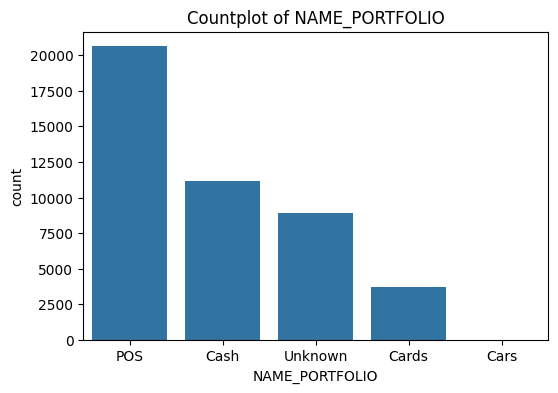

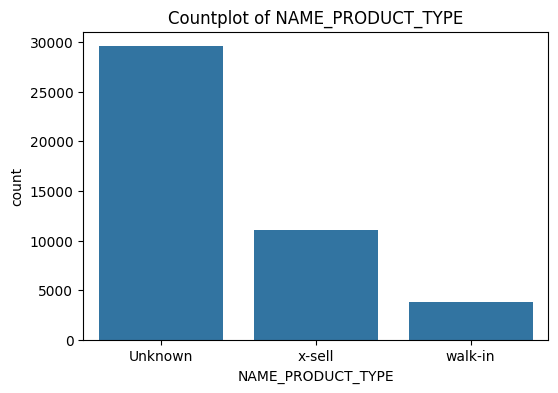

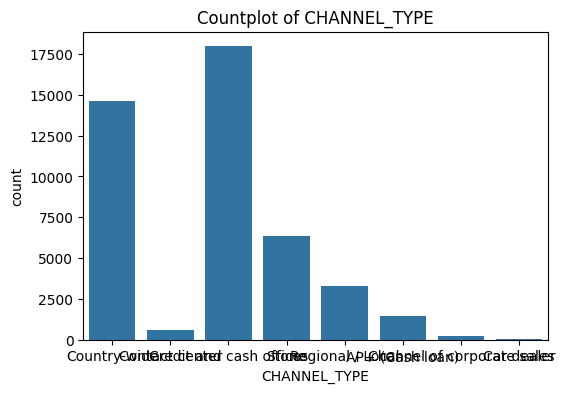

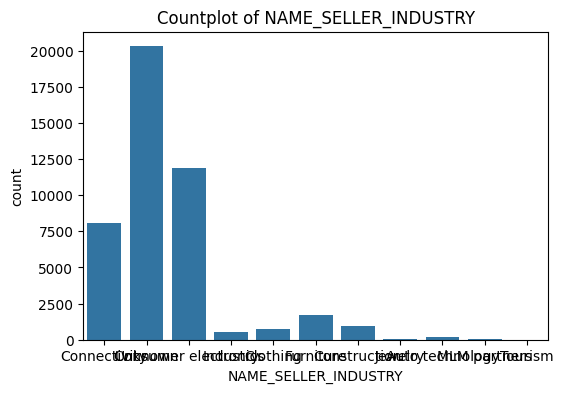

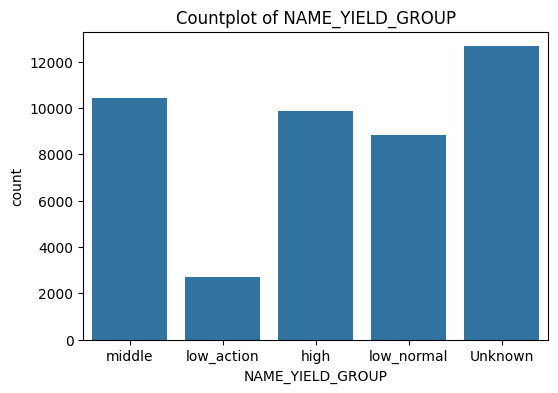

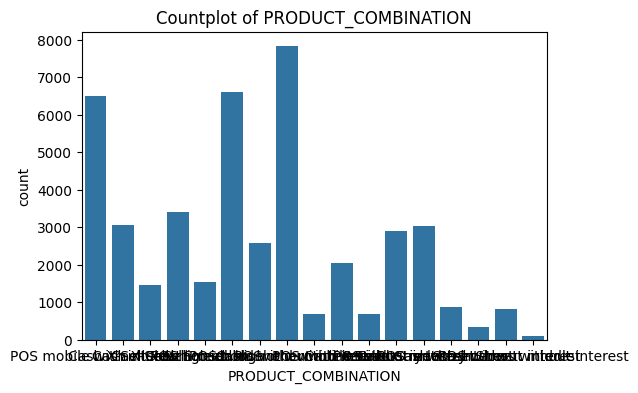

In [900]:
for column in df.select_dtypes(include='object').columns:
  plt.figure(figsize=(6,4))
  sns.countplot(x=column, data=df)
  plt.title(f'Countplot of {column}')
  plt.show()

In [901]:
num_columns=df.select_dtypes(exclude='object').columns[1:]
cat_columns=df.select_dtypes(include='object').columns

In [902]:
cat_columns,len(cat_columns)

(Index(['NAME_CONTRACT_TYPE', 'WEEKDAY_APPR_PROCESS_START',
        'FLAG_LAST_APPL_PER_CONTRACT', 'NAME_CASH_LOAN_PURPOSE',
        'NAME_CONTRACT_STATUS', 'NAME_PAYMENT_TYPE', 'CODE_REJECT_REASON',
        'NAME_TYPE_SUITE', 'NAME_CLIENT_TYPE', 'NAME_GOODS_CATEGORY',
        'NAME_PORTFOLIO', 'NAME_PRODUCT_TYPE', 'CHANNEL_TYPE',
        'NAME_SELLER_INDUSTRY', 'NAME_YIELD_GROUP', 'PRODUCT_COMBINATION'],
       dtype='object'),
 16)

In [903]:
num_columns,len(num_columns)

(Index(['AMT_APPLICATION', 'AMT_CREDIT', 'AMT_DOWN_PAYMENT', 'AMT_GOODS_PRICE',
        'HOUR_APPR_PROCESS_START', 'NFLAG_LAST_APPL_IN_DAY',
        'RATE_DOWN_PAYMENT', 'DAYS_DECISION', 'SELLERPLACE_AREA', 'CNT_PAYMENT',
        'DAYS_FIRST_DRAWING', 'DAYS_FIRST_DUE', 'DAYS_LAST_DUE_1ST_VERSION',
        'DAYS_LAST_DUE', 'DAYS_TERMINATION', 'NFLAG_INSURED_ON_APPROVAL'],
       dtype='object'),
 16)

In [904]:
num_bivariate_columns = [
    'AMT_APPLICATION',
    'AMT_CREDIT',
    'AMT_GOODS_PRICE',
    'AMT_DOWN_PAYMENT',
    'CNT_PAYMENT'
]

In [905]:
num_num_columns = [
    ('AMT_APPLICATION', 'AMT_CREDIT'),
    ('AMT_GOODS_PRICE', 'AMT_CREDIT'),
    ('AMT_CREDIT', 'CNT_PAYMENT'),
    ('AMT_APPLICATION', 'AMT_DOWN_PAYMENT')
    
]

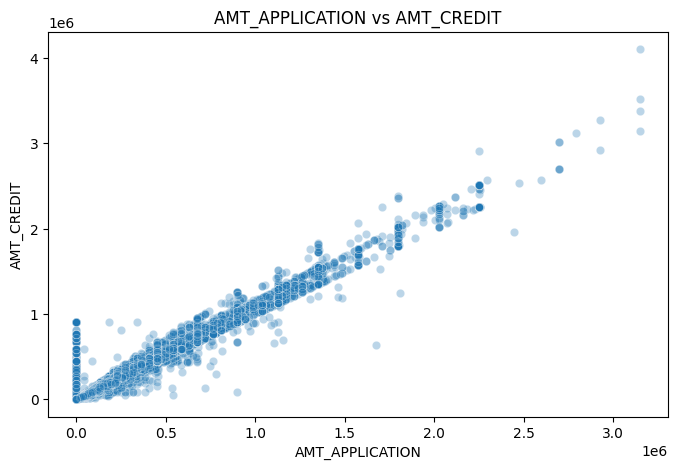

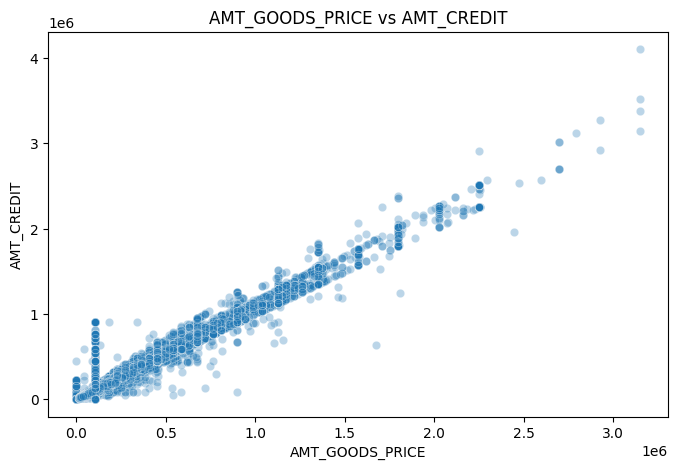

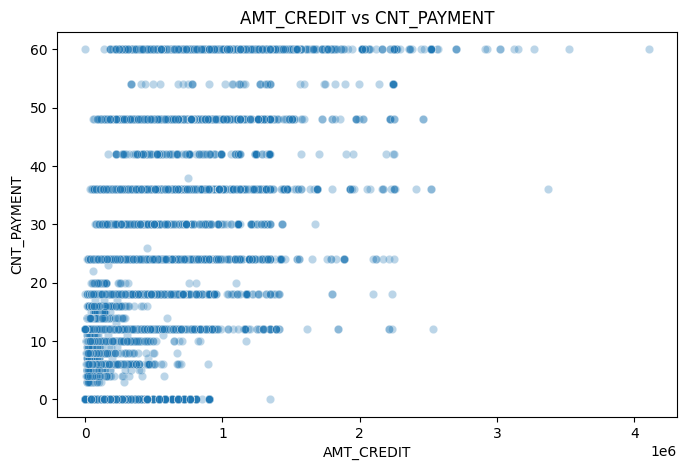

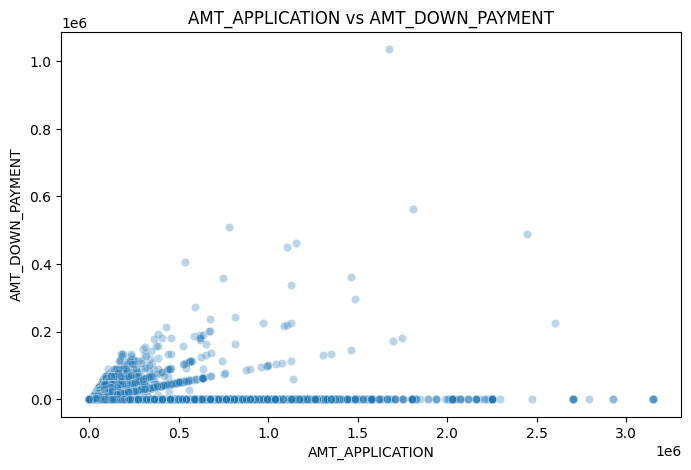

In [906]:
for x,y in num_num_columns:
    

    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        x=x,
        y=y,
        data=df,
        alpha=0.3
    )

    plt.title(f'{x} vs {y}')
    plt.xlabel(x)
    plt.ylabel(y)
    plt.show()

In [907]:
#The scatter plot of `AMT_APPLICATION` vs `AMT_CREDIT` shows a strong positive correlation, indicating that the approved credit amount generally increases with the requested application amount. Most data points are concentrated along an upward trend, suggesting that financial institutions tend to approve higher credit amounts for applications requesting larger loans. A few outliers are also observed.

In [908]:
#The scatter plot of `AMT_GOODS_PRICE` vs `AMT_CREDIT` shows a strong positive correlation, indicating that the credit amount generally increases with the price of the goods. Most data points follow a clear upward trend, suggesting that higher-priced goods are associated with higher credit amounts. A few outliers are also observed.

In [ ]:
#he scatter plot of `AMT_CREDIT` vs `CNT_PAYMENT` shows that higher credit amounts are generally associated with a larger number of repayment installments. However, the data points are widely distributed across different installment counts, indicating that repayment duration varies among loan applicants. Most applications are concentrated at lower credit amounts, with installment periods commonly ranging from 6 to 60 months.

NameError: name 'T' is not defined

In [ ]:
#The scatter plot of `AMT_APPLICATION` vs `AMT_DOWN_PAYMENT` shows a weak positive relationship, indicating that down payment amounts generally increase with the loan application amount. However, many applications have zero down payment, while a few records show unusually high down payment values. This suggests considerable variation in down payment behaviour among loan applicants.

In [ ]:
for x, y in num_num_columns:

    corr = df[x].corr(df[y])

    print(f'Correlation between {x} and {y}: {corr:.2f}')

Correlation between AMT_APPLICATION and AMT_CREDIT: 0.97
Correlation between AMT_GOODS_PRICE and AMT_CREDIT: 0.97
Correlation between AMT_CREDIT and CNT_PAYMENT: 0.66
Correlation between AMT_APPLICATION and AMT_DOWN_PAYMENT: 0.06


In [ ]:
correlation = df[num_bivariate_columns].corr()

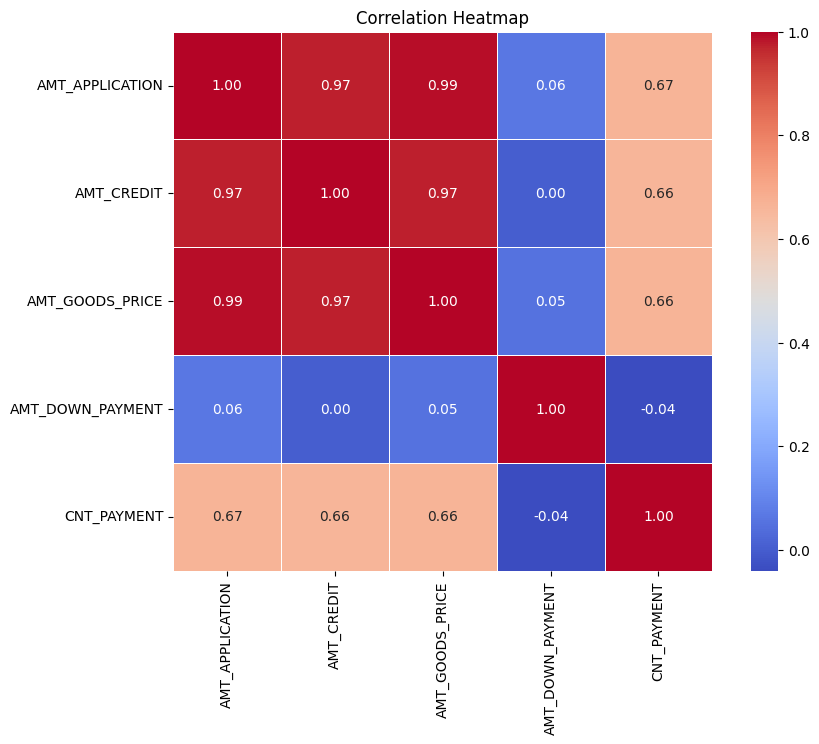

In [ ]:
plt.figure(figsize=(10, 7))

Correlation = df[num_bivariate_columns].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    square=True
)

plt.title('Correlation Heatmap')
plt.show()

In [ ]:
cat_num_columns = [
    ('NAME_CONTRACT_STATUS', 'AMT_CREDIT'),
    ('NAME_CONTRACT_TYPE', 'AMT_CREDIT'),
    ('NAME_CLIENT_TYPE', 'AMT_APPLICATION'),
    ('NAME_PORTFOLIO', 'AMT_CREDIT'),
    ('NAME_YIELD_GROUP', 'RATE_DOWN_PAYMENT')
]

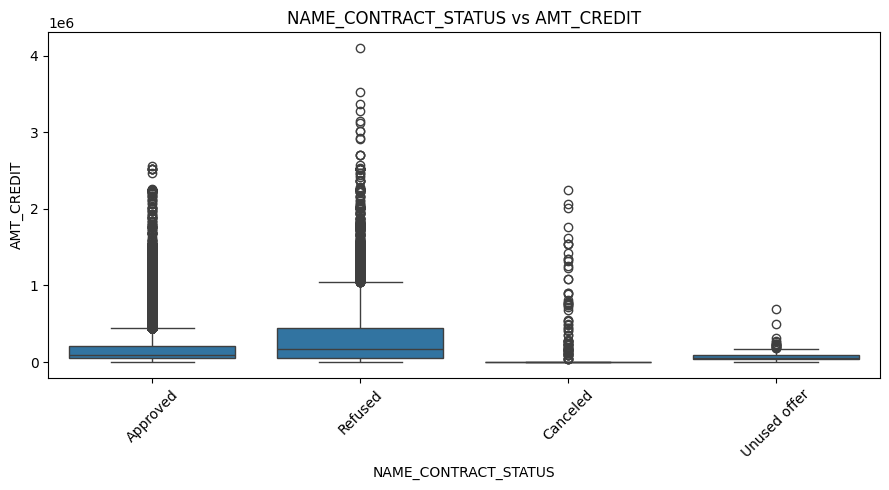

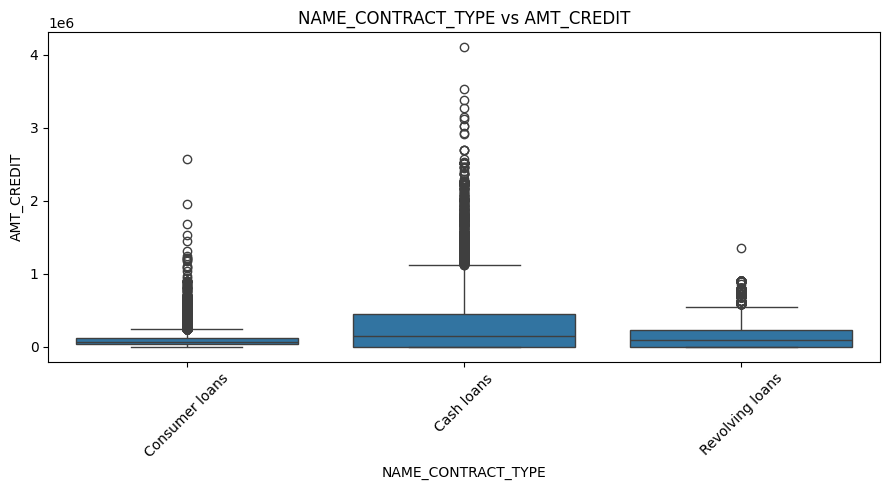

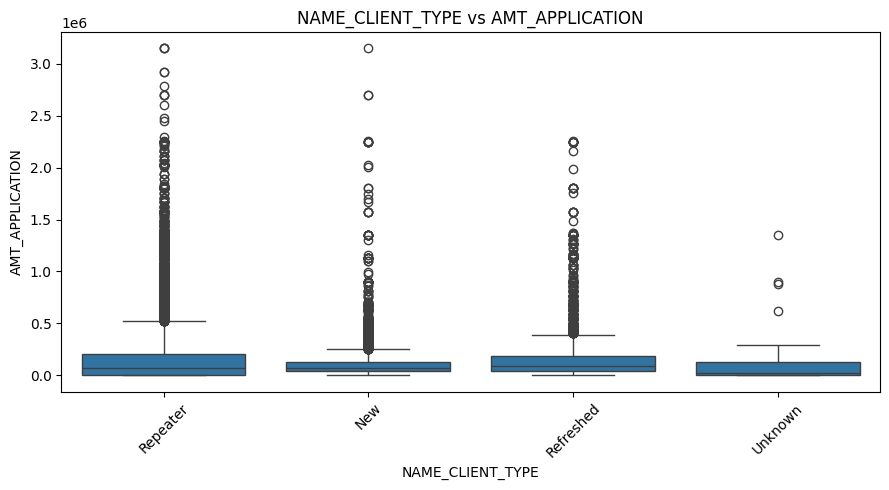

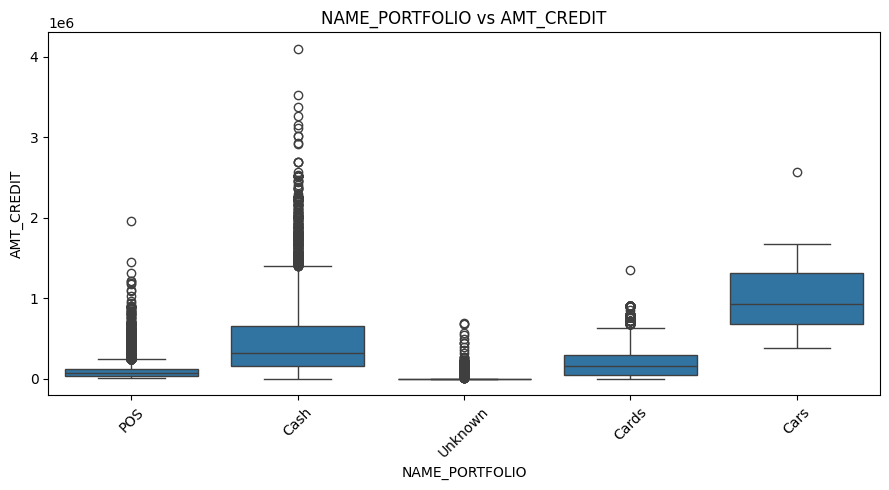

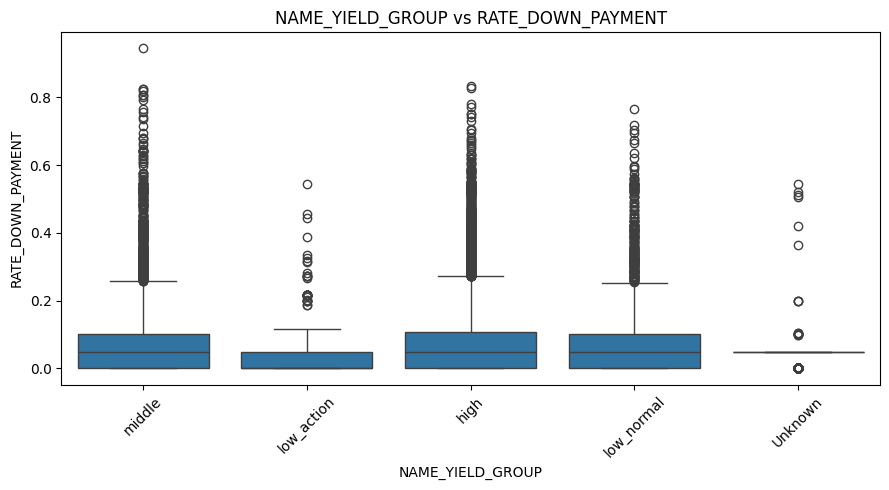

In [ ]:
for x, y in cat_num_columns:

    plt.figure(figsize=(9, 5))

    sns.boxplot(
        x=x,
        y=y,
        data=df
    )

    plt.title(f'{x} vs {y}')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [ ]:
for cat_columns, num_columns in cat_num_columns:

    groups = [
        group[num_columns].dropna()
        for _, group in df.groupby(cat_columns)
    ]

    groups = [group for group in groups if len(group) > 0]

    f_stat, p_value = f_oneway(*groups)

    print(f'\n{cat_columns} vs {num_columns}')
    print('F-Statistic:', round(f_stat, 4))
    print('P-value:', round(p_value, 6))

    if p_value < 0.05:
        print('Reject H0: Significant difference between group means.')
    else:
        print('Fail to reject H0: No significant difference between group means.')


NAME_CONTRACT_STATUS vs AMT_CREDIT
F-Statistic: 1794.923
P-value: 0.0
Reject H0: Significant difference between group means.

NAME_CONTRACT_TYPE vs AMT_CREDIT
F-Statistic: 2711.9061
P-value: 0.0
Reject H0: Significant difference between group means.

NAME_CLIENT_TYPE vs AMT_APPLICATION
F-Statistic: 183.1098
P-value: 0.0
Reject H0: Significant difference between group means.

NAME_PORTFOLIO vs AMT_CREDIT
F-Statistic: 6292.6412
P-value: 0.0
Reject H0: Significant difference between group means.

NAME_YIELD_GROUP vs RATE_DOWN_PAYMENT
F-Statistic: 731.2145
P-value: 0.0
Reject H0: Significant difference between group means.


In [956]:
for cat_col, num_col in cat_num_columns:

    print(f'\n{cat_col} vs {num_col}')

    display(
        df.groupby(cat_col)[num_col]
        .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
        .round(2)
    )


NAME_CONTRACT_STATUS vs AMT_CREDIT


KeyError: 'NAME_CONTRACT_STATUS'

In [ ]:
#The box plot of `NAME_CONTRACT_STATUS` vs `AMT_CREDIT` shows that refused applications have a higher median credit amount and wider distribution compared to approved applications. Cancelled applications generally have very low credit amounts, while unused offers show relatively lower credit amounts. Several outliers are observed across all categories, indicating variations in credit amounts among loan applications.

In [ ]:
#The box plot of `NAME_CONTRACT_TYPE` vs `AMT_CREDIT` shows that cash loans have the highest median credit amount and the widest distribution compared to consumer and revolving loans. Consumer loans have comparatively lower median credit amounts, while revolving loans show moderate credit amounts. Several extreme outliers are observed across all contract types, indicating significant variations in credit amounts among different loan categories.

In [ ]:
#The box plot of `NAME_CLIENT_TYPE` vs `AMT_APPLICATION` shows that repeat clients have a higher median application amount compared to new clients. Refreshed clients also show relatively higher application amounts, while new clients have a comparatively lower median. Several extreme outliers are observed across all categories, indicating significant variations in loan application amounts among different client types.

In [ ]:
#The box plot of `NAME_PORTFOLIO` vs `AMT_CREDIT` shows that car loan applications have the highest median credit amount, followed by cash and card loans. POS loans have comparatively lower median credit amounts, while unknown portfolio categories show very low credit amounts. Several outliers are observed, particularly in cash and POS portfolios, indicating significant variations in credit amounts across different loan portfolios.

In [ ]:
#The box plot of `NAME_YIELD_GROUP` vs `RATE_DOWN_PAYMENT` shows that the middle, high and low-normal yield groups have relatively similar median down payment rates. The low-action group shows a comparatively lower median, while the unknown category has very limited variation. Several outliers are observed across the yield groups, indicating differences in down payment behaviour among loan applicants.


In [ ]:
cat_cat_columns = [
    ('NAME_CONTRACT_TYPE', 'NAME_CONTRACT_STATUS'),
    ('NAME_CLIENT_TYPE', 'NAME_CONTRACT_STATUS'),
    ('NAME_PORTFOLIO', 'NAME_CONTRACT_STATUS'),
    ('NAME_PAYMENT_TYPE', 'NAME_CONTRACT_STATUS'),
    ('CHANNEL_TYPE', 'NAME_CONTRACT_STATUS')
]

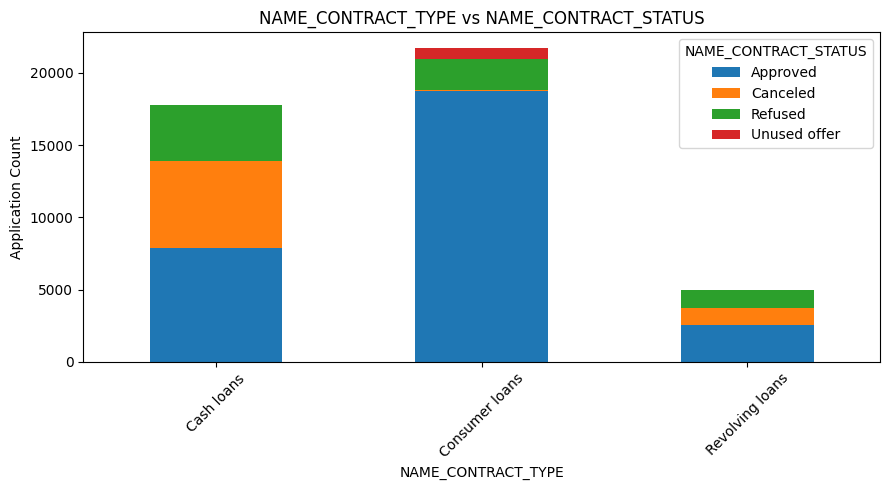

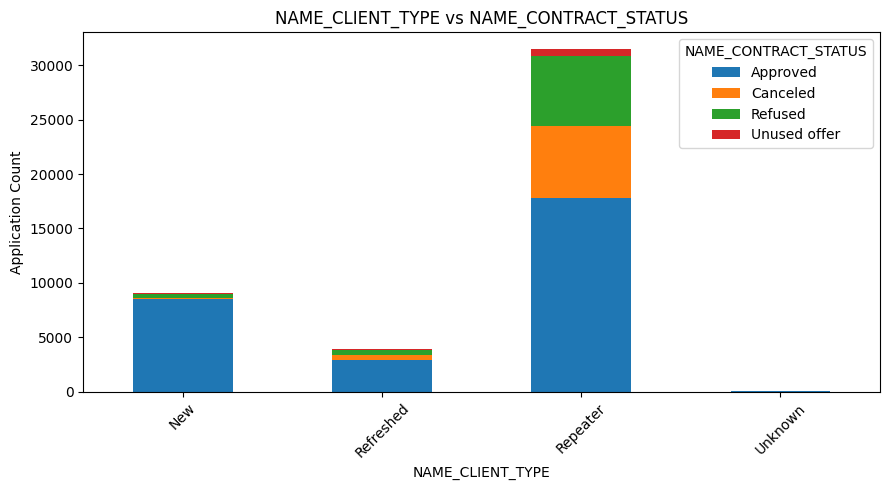

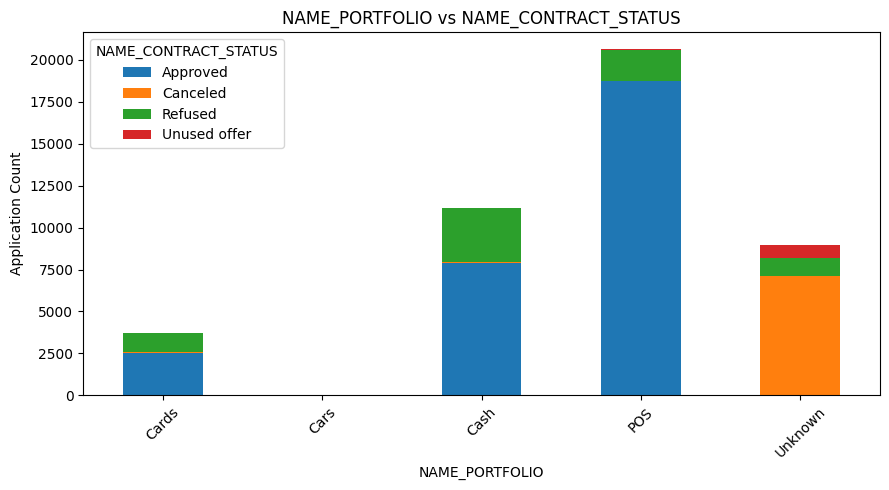

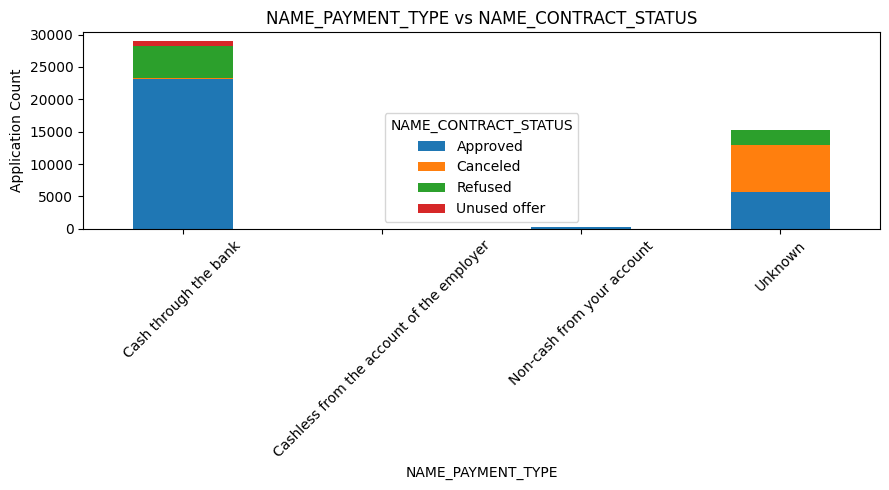

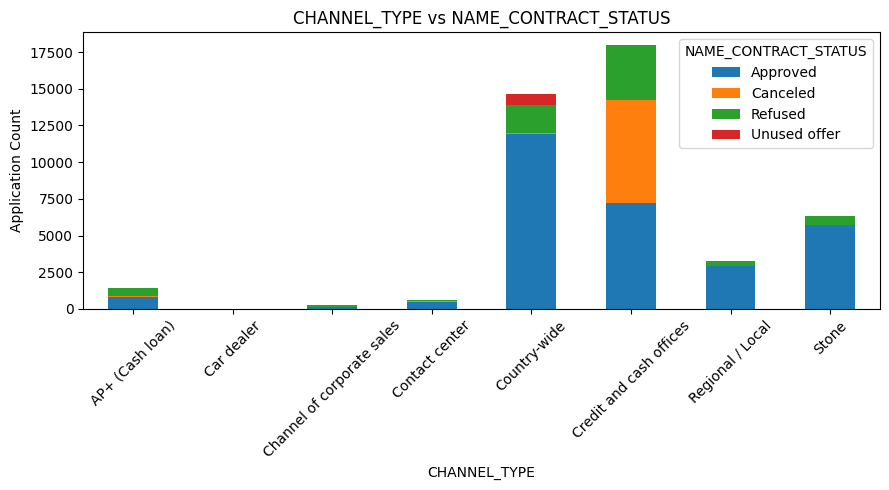

In [ ]:
for x, y in cat_cat_columns:

    ct = pd.crosstab(df[x], df[y])

    ct.plot(
        kind='bar',
        stacked=True,
        figsize=(9, 5)
    )

    plt.title(f'{x} vs {y}')
    plt.xlabel(x)
    plt.ylabel('Application Count')
    plt.xticks(rotation=45)
    plt.legend(title=y)
    plt.tight_layout()
    plt.show()




In [ ]:

ct = pd.crosstab(df[x], df[y], normalize='index') * 100

In [ ]:
#The relationship between **NAME_CONTRACT_TYPE** and **NAME_CONTRACT_STATUS** shows that consumer loans have the highest number of applications, with the majority being approved, followed by a smaller number of refused and unused offers. Cash loans have a comparatively higher proportion of cancelled and refused applications, while revolving loans have the lowest overall application count. This indicates that consumer loans have a higher approval count, whereas cash loans show a greater number of unsuccessful or cancelled applications.

In [ ]:
#The relationship between **NAME_CLIENT_TYPE** and **NAME_CONTRACT_STATUS** shows that repeat clients account for the highest number of previous loan applications, followed by new and refreshed clients. Among repeat clients, approved applications are the highest, although a considerable number of applications were also refused or cancelled. New and refreshed clients have comparatively fewer applications, with approvals forming the largest share in both categories. This indicates that repeat clients contribute significantly to the previous loan application records and account for the highest number of approved applications.

In [ ]:
#The relationship between **NAME_PORTFOLIO** and **NAME_CONTRACT_STATUS** shows that POS accounts for the highest number of previous loan applications, with the majority being approved, followed by a smaller number of refused applications. Cash portfolio applications also show a considerable number of approvals and refusals. The Cards category has fewer applications, while the Unknown category has a higher number of cancelled applications and unused offers. This indicates that POS and Cash portfolios contribute significantly to approved loan applications, whereas the Unknown category has a comparatively higher number of cancelled applications.

In [ ]:
#The relationship between **NAME_PAYMENT_TYPE** and **NAME_CONTRACT_STATUS** shows that applications using 'Cash through the bank' have the highest number of records, with the majority being approved, followed by refused applications. Applications with an 'Unknown' payment type have a considerable number of cancelled applications, along with some refused applications. Other payment methods account for very few applications. This indicates that bank-based cash payments are the most common payment method among previous loan applications, while applications with unknown payment types show a higher proportion of cancellations.

In [ ]:
#The relationship between **CHANNEL_TYPE** and **NAME_CONTRACT_STATUS** shows that Country-wide and Credit and Cash Offices account for the highest number of previous loan applications. Country-wide applications have a higher number of approvals, whereas Credit and Cash Offices show a considerable number of cancelled and refused applications. Regional / Local and Stone channels have comparatively fewer applications, with approvals forming the majority of their records. This indicates that loan application outcomes vary across different distribution channels, with Credit and Cash Offices recording a relatively higher number of cancelled applications.

In [914]:
username='root'
password='1234'
host='localhost'
database='credit_risk_analysis'
engine=create_engine(f"mysql+pymysql://{username}:{password}@{host}/{database}",echo=False)
#connection_url = f"mysql+pymysql://{user}:{password}@{host}:{port}/{database}"

df.to_sql('loan_data',con=engine,if_exists='replace',index=False)

44471

In [ ]:
#basic queries

In [915]:
df=pd.read_sql('SELECT * FROM loan_data',con=engine)

In [916]:
df

,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,FLAG_LAST_APPL_PER_CONTRACT,NFLAG_LAST_APPL_IN_DAY,...,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,Consumer loans,10737.83,17145.00,17145.00,0.00,17145.00,SATURDAY,15,Y,1,...,Connectivity,12.00,middle,POS mobile with interest,365243.00,-42.00,300.00,-42.00,-37.00,0.00
1,Cash loans,10737.83,607500.00,679671.00,1575.00,607500.00,THURSDAY,11,Y,1,...,Unknown,36.00,low_action,Cash X-Sell: low,365243.00,-134.00,916.00,365243.00,365243.00,1.00
2,Cash loans,10737.83,112500.00,136444.50,1575.00,112500.00,TUESDAY,11,Y,1,...,Unknown,12.00,high,Cash X-Sell: high,365243.00,-271.00,59.00,365243.00,365243.00,1.00
3,Cash loans,10737.83,450000.00,470790.00,1575.00,450000.00,MONDAY,7,Y,1,...,Unknown,12.00,middle,Cash X-Sell: middle,365243.00,-482.00,-152.00,-182.00,-177.00,1.00
4,Cash loans,10737.83,337500.00,404055.00,1575.00,337500.00,THURSDAY,9,Y,1,...,Unknown,24.00,high,Cash Street: high,365243.00,-823.00,-369.00,-537.00,-501.00,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44466,Cash loans,10737.83,1125000.00,1125000.00,1575.00,1125000.00,MONDAY,8,Y,1,...,Unknown,60.00,low_normal,Cash Street: low,365243.00,-823.00,-369.00,-537.00,-501.00,0.00
44467,Cash loans,10737.83,1260000.00,1260000.00,1575.00,1260000.00,WEDNESDAY,5,Y,1,...,Unknown,60.00,low_normal,Cash Street: low,365243.00,-823.00,-369.00,-537.00,-501.00,0.00
44468,Consumer loans,10737.83,87612.30,87610.50,1.80,87612.30,WEDNESDAY,19,Y,1,...,Consumer electronics,24.00,low_action,POS household without interest,365243.00,-1140.00,-450.00,-540.00,-537.00,0.00
44469,Cash loans,10737.83,0.00,0.00,1575.00,102055.50,FRIDAY,10,Y,1,...,Unknown,12.00,Unknown,Cash,365243.00,-823.00,-369.00,-537.00,-501.00,0.00


In [ ]:
#Retrieve all records from the loan_data table.


In [917]:
df=pd.read_sql('SELECT * FROM loan_data WHERE NAME_CONTRACT_TYPE="Cash loans" ',con=engine)

In [ ]:
df

,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,FLAG_LAST_APPL_PER_CONTRACT,NFLAG_LAST_APPL_IN_DAY,...,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,Cash loans,10737.83,607500.00,679671.00,1575.00,607500.00,THURSDAY,11,Y,1,...,Unknown,36.00,low_action,Cash X-Sell: low,365243.00,-134.00,916.00,365243.00,365243.00,1.00
1,Cash loans,10737.83,112500.00,136444.50,1575.00,112500.00,TUESDAY,11,Y,1,...,Unknown,12.00,high,Cash X-Sell: high,365243.00,-271.00,59.00,365243.00,365243.00,1.00
2,Cash loans,10737.83,450000.00,470790.00,1575.00,450000.00,MONDAY,7,Y,1,...,Unknown,12.00,middle,Cash X-Sell: middle,365243.00,-482.00,-152.00,-182.00,-177.00,1.00
3,Cash loans,10737.83,337500.00,404055.00,1575.00,337500.00,THURSDAY,9,Y,1,...,Unknown,24.00,high,Cash Street: high,365243.00,-823.00,-369.00,-537.00,-501.00,0.00
4,Cash loans,10737.83,315000.00,340573.50,1575.00,315000.00,SATURDAY,8,Y,1,...,Unknown,18.00,low_normal,Cash X-Sell: low,365243.00,-654.00,-144.00,-144.00,-137.00,1.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17770,Cash loans,10737.83,63000.00,67158.00,1575.00,63000.00,SATURDAY,18,Y,1,...,Connectivity,12.00,high,Cash X-Sell: high,365243.00,-736.00,-406.00,-406.00,-401.00,1.00
17771,Cash loans,10737.83,1125000.00,1125000.00,1575.00,1125000.00,MONDAY,8,Y,1,...,Unknown,60.00,low_normal,Cash Street: low,365243.00,-823.00,-369.00,-537.00,-501.00,0.00
17772,Cash loans,10737.83,1260000.00,1260000.00,1575.00,1260000.00,WEDNESDAY,5,Y,1,...,Unknown,60.00,low_normal,Cash Street: low,365243.00,-823.00,-369.00,-537.00,-501.00,0.00
17773,Cash loans,10737.83,0.00,0.00,1575.00,102055.50,FRIDAY,10,Y,1,...,Unknown,12.00,Unknown,Cash,365243.00,-823.00,-369.00,-537.00,-501.00,0.00


In [ ]:


#Display all loan applications with their contract type and contract status






In [918]:
df=pd.read_sql('SELECT NAME_CONTRACT_TYPE AND NAME_CONTRACT_STATUS FROM loan_data',con=engine)

In [ ]:
df

,NAME_CONTRACT_TYPE AND NAME_CONTRACT_STATUS
0,0
1,0
2,0
3,0
4,0
...,...
44466,0
44467,0
44468,0
44469,0


In [ ]:
#Retrieve all applications where the contract status is 'Approved'.



In [919]:
df=pd.read_sql('SELECT * FROM loan_data WHERE NAME_CONTRACT_STATUS="Approved"',con=engine)
df

,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,FLAG_LAST_APPL_PER_CONTRACT,NFLAG_LAST_APPL_IN_DAY,...,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,Consumer loans,10737.83,17145.00,17145.00,0.00,17145.00,SATURDAY,15,Y,1,...,Connectivity,12.00,middle,POS mobile with interest,365243.00,-42.00,300.00,-42.00,-37.00,0.00
1,Cash loans,10737.83,607500.00,679671.00,1575.00,607500.00,THURSDAY,11,Y,1,...,Unknown,36.00,low_action,Cash X-Sell: low,365243.00,-134.00,916.00,365243.00,365243.00,1.00
2,Cash loans,10737.83,112500.00,136444.50,1575.00,112500.00,TUESDAY,11,Y,1,...,Unknown,12.00,high,Cash X-Sell: high,365243.00,-271.00,59.00,365243.00,365243.00,1.00
3,Cash loans,10737.83,450000.00,470790.00,1575.00,450000.00,MONDAY,7,Y,1,...,Unknown,12.00,middle,Cash X-Sell: middle,365243.00,-482.00,-152.00,-182.00,-177.00,1.00
4,Cash loans,10737.83,315000.00,340573.50,1575.00,315000.00,SATURDAY,8,Y,1,...,Unknown,18.00,low_normal,Cash X-Sell: low,365243.00,-654.00,-144.00,-144.00,-137.00,1.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29193,Cash loans,10737.83,63000.00,67158.00,1575.00,63000.00,SATURDAY,18,Y,1,...,Connectivity,12.00,high,Cash X-Sell: high,365243.00,-736.00,-406.00,-406.00,-401.00,1.00
29194,Consumer loans,10737.83,151209.00,160155.00,15124.50,151209.00,SATURDAY,12,Y,1,...,Consumer electronics,24.00,middle,POS household with interest,365243.00,-2260.00,-1570.00,-1840.00,-1836.00,1.00
29195,Consumer loans,10737.83,28210.50,26896.50,2821.50,28210.50,FRIDAY,8,Y,1,...,Connectivity,6.00,high,POS mobile with interest,365243.00,-245.00,-95.00,-95.00,-85.00,0.00
29196,Consumer loans,10737.83,36576.00,35635.50,3658.50,36576.00,THURSDAY,15,Y,1,...,Consumer electronics,10.00,low_normal,POS household without interest,365243.00,-2874.00,-2604.00,-2604.00,-2601.00,1.00


In [ ]:
#Display all applications where the contract status is 'Refused'.


In [920]:
df=pd.read_sql('SELECT * FROM loan_data  WHERE NAME_CONTRACT_STATUS="Refused"',con=engine)
df

,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,FLAG_LAST_APPL_PER_CONTRACT,NFLAG_LAST_APPL_IN_DAY,...,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,Cash loans,10737.83,337500.00,404055.00,1575.00,337500.00,THURSDAY,9,Y,1,...,Unknown,24.00,high,Cash Street: high,365243.00,-823.00,-369.00,-537.00,-501.00,0.00
1,Cash loans,10737.83,45000.00,49455.00,1575.00,45000.00,SATURDAY,16,Y,1,...,Unknown,18.00,high,Cash Street: high,365243.00,-823.00,-369.00,-537.00,-501.00,0.00
2,Cash loans,10737.83,450000.00,491580.00,1575.00,450000.00,MONDAY,6,Y,1,...,Unknown,24.00,low_normal,Cash X-Sell: low,365243.00,-823.00,-369.00,-537.00,-501.00,0.00
3,Cash loans,10737.83,0.00,0.00,1575.00,102055.50,TUESDAY,9,Y,1,...,Unknown,12.00,Unknown,Cash,365243.00,-823.00,-369.00,-537.00,-501.00,0.00
4,Cash loans,10737.83,0.00,0.00,1575.00,102055.50,WEDNESDAY,15,Y,1,...,Unknown,12.00,Unknown,Cash,365243.00,-823.00,-369.00,-537.00,-501.00,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7296,Cash loans,10737.83,360000.00,398016.00,1575.00,360000.00,WEDNESDAY,12,Y,1,...,Unknown,24.00,middle,Cash X-Sell: middle,365243.00,-823.00,-369.00,-537.00,-501.00,0.00
7297,Consumer loans,10737.83,214191.00,192771.00,21420.00,214191.00,SATURDAY,17,Y,1,...,Consumer electronics,10.00,low_normal,POS household without interest,365243.00,-823.00,-369.00,-537.00,-501.00,0.00
7298,Cash loans,10737.83,1125000.00,1125000.00,1575.00,1125000.00,MONDAY,8,Y,1,...,Unknown,60.00,low_normal,Cash Street: low,365243.00,-823.00,-369.00,-537.00,-501.00,0.00
7299,Cash loans,10737.83,1260000.00,1260000.00,1575.00,1260000.00,WEDNESDAY,5,Y,1,...,Unknown,60.00,low_normal,Cash Street: low,365243.00,-823.00,-369.00,-537.00,-501.00,0.00


In [ ]:
#Retrieve all applications belonging to the 'Repeater' client type.


In [921]:
df=pd.read_sql('SELECT * FROM loan_data WHERE NAME_CLIENT_TYPE="Repeater"',con=engine)
df

,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,FLAG_LAST_APPL_PER_CONTRACT,NFLAG_LAST_APPL_IN_DAY,...,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,Consumer loans,10737.83,17145.00,17145.00,0.00,17145.00,SATURDAY,15,Y,1,...,Connectivity,12.00,middle,POS mobile with interest,365243.00,-42.00,300.00,-42.00,-37.00,0.00
1,Cash loans,10737.83,607500.00,679671.00,1575.00,607500.00,THURSDAY,11,Y,1,...,Unknown,36.00,low_action,Cash X-Sell: low,365243.00,-134.00,916.00,365243.00,365243.00,1.00
2,Cash loans,10737.83,112500.00,136444.50,1575.00,112500.00,TUESDAY,11,Y,1,...,Unknown,12.00,high,Cash X-Sell: high,365243.00,-271.00,59.00,365243.00,365243.00,1.00
3,Cash loans,10737.83,450000.00,470790.00,1575.00,450000.00,MONDAY,7,Y,1,...,Unknown,12.00,middle,Cash X-Sell: middle,365243.00,-482.00,-152.00,-182.00,-177.00,1.00
4,Cash loans,10737.83,337500.00,404055.00,1575.00,337500.00,THURSDAY,9,Y,1,...,Unknown,24.00,high,Cash Street: high,365243.00,-823.00,-369.00,-537.00,-501.00,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31483,Cash loans,10737.83,63000.00,67158.00,1575.00,63000.00,SATURDAY,18,Y,1,...,Connectivity,12.00,high,Cash X-Sell: high,365243.00,-736.00,-406.00,-406.00,-401.00,1.00
31484,Consumer loans,10737.83,214191.00,192771.00,21420.00,214191.00,SATURDAY,17,Y,1,...,Consumer electronics,10.00,low_normal,POS household without interest,365243.00,-823.00,-369.00,-537.00,-501.00,0.00
31485,Cash loans,10737.83,1125000.00,1125000.00,1575.00,1125000.00,MONDAY,8,Y,1,...,Unknown,60.00,low_normal,Cash Street: low,365243.00,-823.00,-369.00,-537.00,-501.00,0.00
31486,Cash loans,10737.83,0.00,0.00,1575.00,102055.50,FRIDAY,10,Y,1,...,Unknown,12.00,Unknown,Cash,365243.00,-823.00,-369.00,-537.00,-501.00,0.00


#🔹 Aggregation Queries


In [ ]:
#Calculate the total number of loan applications.


In [922]:
df=pd.read_sql('SELECT COUNT(*) AS total_loan_applications FROM loan_data',con=engine)
df

,total_loan_applications
0,44471


In [ ]:
#Calculate the total credit amount across all applications.


In [923]:
df=pd.read_sql('SELECT SUM(AMT_CREDIT) AS total_credit_amount FROM loan_data',con=engine)
df

,total_credit_amount
0,8264863343.97


In [ ]:
#Calculate the average loan application amount.


In [924]:
df=pd.read_sql('SELECT AVG(AMT_APPLICATION) AS average_loan_application FROM loan_data',con=engine)
df

,average_loan_application
0,166679.06


In [ ]:
#Count the number of applications for each contract status.


In [935]:
df=pd.read_sql('SELECT NAME_CONTRACT_STATUS ,COUNT(*) AS total_application FROM loan_data GROUP BY NAME_CONTRACT_STATUS ORDER BY total_application DESC',con=engine)
df

,NAME_CONTRACT_STATUS,total_application
0,Approved,29198
1,Refused,7301
2,Canceled,7198
3,Unused offer,774


In [ ]:
#Calculate the average annuity amount for each contract type.

In [937]:
df=pd.read_sql('SELECT NAME_CONTRACT_TYPE,AVG(AMT_ANNUITY) AS  avg_amt_annuity FROM loan_data GROUP BY NAME_CONTRACT_TYPE ORDER BY avg_amt_annuity DESC',con=engine)
df

,NAME_CONTRACT_TYPE,avg_amt_annuity
0,Consumer loans,10737.83
1,Cash loans,10737.83
2,Revolving loans,10737.83
3,None,10737.83


In [ ]:
#🔹 Join-Based Queries


In [ ]:
#Retrieve loan applications where the credit amount is greater than 500,000.


In [939]:
df=pd.read_sql('SELECT * FROM loan_data WHERE AMT_CREDIT>50000',con=engine)
df

,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,FLAG_LAST_APPL_PER_CONTRACT,NFLAG_LAST_APPL_IN_DAY,...,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,Cash loans,10737.83,607500.00,679671.00,1575.00,607500.00,THURSDAY,11,Y,1,...,Unknown,36.00,low_action,Cash X-Sell: low,365243.00,-134.00,916.00,365243.00,365243.00,1.00
1,Cash loans,10737.83,112500.00,136444.50,1575.00,112500.00,TUESDAY,11,Y,1,...,Unknown,12.00,high,Cash X-Sell: high,365243.00,-271.00,59.00,365243.00,365243.00,1.00
2,Cash loans,10737.83,450000.00,470790.00,1575.00,450000.00,MONDAY,7,Y,1,...,Unknown,12.00,middle,Cash X-Sell: middle,365243.00,-482.00,-152.00,-182.00,-177.00,1.00
3,Cash loans,10737.83,337500.00,404055.00,1575.00,337500.00,THURSDAY,9,Y,1,...,Unknown,24.00,high,Cash Street: high,365243.00,-823.00,-369.00,-537.00,-501.00,0.00
4,Cash loans,10737.83,315000.00,340573.50,1575.00,315000.00,SATURDAY,8,Y,1,...,Unknown,18.00,low_normal,Cash X-Sell: low,365243.00,-654.00,-144.00,-144.00,-137.00,1.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27321,Consumer loans,10737.83,214191.00,192771.00,21420.00,214191.00,SATURDAY,17,Y,1,...,Consumer electronics,10.00,low_normal,POS household without interest,365243.00,-823.00,-369.00,-537.00,-501.00,0.00
27322,Cash loans,10737.83,1125000.00,1125000.00,1575.00,1125000.00,MONDAY,8,Y,1,...,Unknown,60.00,low_normal,Cash Street: low,365243.00,-823.00,-369.00,-537.00,-501.00,0.00
27323,Cash loans,10737.83,1260000.00,1260000.00,1575.00,1260000.00,WEDNESDAY,5,Y,1,...,Unknown,60.00,low_normal,Cash Street: low,365243.00,-823.00,-369.00,-537.00,-501.00,0.00
27324,Consumer loans,10737.83,87612.30,87610.50,1.80,87612.30,WEDNESDAY,19,Y,1,...,Consumer electronics,24.00,low_action,POS household without interest,365243.00,-1140.00,-450.00,-540.00,-537.00,0.00


In [ ]:
#Find applications where the down payment amount is greater than 50,000.


In [940]:
df=pd.read_sql('SELECT * FROM loan_data WHERE AMT_DOWN_PAYMENT>50000',con=engine)
df

,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,FLAG_LAST_APPL_PER_CONTRACT,NFLAG_LAST_APPL_IN_DAY,...,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,Consumer loans,10737.83,103455.00,54459.00,51727.50,103455.00,SUNDAY,14,Y,1,...,Consumer electronics,6.00,low_normal,POS household with interest,365243.00,-189.00,-39.00,-159.00,-157.00,0.00
1,Consumer loans,10737.83,91755.00,33718.50,59625.00,91755.00,SATURDAY,10,Y,1,...,Consumer electronics,6.00,low_normal,POS household with interest,365243.00,-2730.00,-2580.00,-2580.00,-2557.00,1.00
2,Consumer loans,10737.83,741375.00,628875.00,112500.00,741375.00,TUESDAY,11,Y,1,...,Furniture,30.00,low_normal,POS industry with interest,365243.00,-823.00,-369.00,-537.00,-501.00,0.00
3,Consumer loans,10737.83,900000.00,810000.00,90000.00,900000.00,WEDNESDAY,16,Y,1,...,Construction,12.00,middle,POS industry with interest,365243.00,-298.00,32.00,-118.00,-115.00,0.00
4,Consumer loans,10737.83,157455.00,99927.00,62982.00,157455.00,WEDNESDAY,16,Y,1,...,Consumer electronics,7.00,middle,POS household with interest,365243.00,-2137.00,-1957.00,-1957.00,-1951.00,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
315,Consumer loans,10737.83,669600.00,494500.50,200880.00,669600.00,THURSDAY,6,Y,1,...,Consumer electronics,10.00,middle,POS household with interest,365243.00,-1565.00,-1295.00,-1295.00,-1292.00,0.00
316,Consumer loans,10737.83,301500.00,241200.00,60300.00,301500.00,TUESDAY,13,Y,1,...,Clothing,6.00,low_normal,POS industry with interest,365243.00,-999.00,-849.00,-849.00,-843.00,0.00
317,Consumer loans,10737.83,541620.00,487458.00,54162.00,541620.00,THURSDAY,16,Y,1,...,Furniture,12.00,middle,POS industry with interest,365243.00,-440.00,-110.00,-290.00,-283.00,0.00
318,Consumer loans,10737.83,175495.50,113697.00,67500.00,175495.50,SUNDAY,10,Y,1,...,Consumer electronics,6.00,middle,POS household with interest,365243.00,-324.00,-174.00,-174.00,-172.00,1.00


In [ ]:
#Count the number of applications for each client type.


In [942]:
df=pd.read_sql('SELECT NAME_CLIENT_TYPE,COUNT(*) AS total_applications FROM loan_data GROUP BY NAME_CLIENT_TYPE ORDER BY total_applications DESC',con=engine)
df

,NAME_CLIENT_TYPE,total_applications
0,Repeater,31488
1,New,9060
2,Refreshed,3875
3,Unknown,48


In [ ]:
#Calculate the average credit amount for each loan contract status.


In [941]:
df=pd.read_sql('SELECT NAME_CONTRACT_STATUS,AVG(AMT_CREDIT) AS avg_credit_amt FROM loan_data GROUP BY NAME_CONTRACT_STATUS ORDER BY avg_credit_amt DESC',con=engine)
df

,NAME_CONTRACT_STATUS,avg_credit_amt
0,Refused,348717.27
1,Approved,192491.68
2,Unused offer,68565.53
3,Canceled,6312.41


In [ ]:
#Find the top 5 product combinations with the highest number of applications.


In [946]:
df=pd.read_sql('SELECT PRODUCT_COMBINATION ,COUNT(*)as total_application FROM loan_data GROUP BY PRODUCT_COMBINATION ORDER BY total_application DESC',con=engine)
df

,PRODUCT_COMBINATION,total_application
0,POS household with interest,7821
1,Cash,6602
2,POS mobile with interest,6497
3,Cash X-Sell: middle,3411
4,Cash X-Sell: low,3057
5,POS industry with interest,3030
6,Card Street,2910
7,POS household without interest,2583
8,Card X-Sell,2042
9,Cash Street: high,1530


In [ ]:
#🔹 Financial Tracking Queries


In [ ]:
#Calculate the total credit amount for approved and refused applications separately.


In [948]:
df=pd.read_sql('SELECT NAME_CONTRACT_STATUS,SUM(AMT_CREDIT) AS total_credit_amount FROM loan_data WHERE NAME_CONTRACT_STATUS IN ("Approved","Refused")GROUP BY NAME_CONTRACT_STATUS ORDER BY total_credit_amount DESC',con=engine)
df

,NAME_CONTRACT_STATUS,total_credit_amount
0,Approved,5620372148.20
1,Refused,2545984767.28


In [ ]:
#Find the top 3 contract types with the highest average credit amount.


In [950]:
df=pd.read_sql('SELECT NAME_CONTRACT_TYPE,AVG(AMT_CREDIT) AS avg_credit_amount FROM loan_data GROUP BY NAME_CONTRACT_TYPE ORDER BY avg_credit_amount DESC LIMIT 3 ',con=engine)
df

,NAME_CONTRACT_TYPE,avg_credit_amount
0,Cash loans,304194.73
1,Revolving loans,172329.46
2,Consumer loans,92208.42


In [ ]:
#Calculate the total application amount for each payment type.


In [951]:
df=pd.read_sql('SELECT NAME_PAYMENT_TYPE,SUM(AMT_APPLICATION) AS total_application_amt  FROM loan_data GROUP BY NAME_PAYMENT_TYPE ORDER BY total_application_amt DESC',con=engine)
df

,NAME_PAYMENT_TYPE,total_application_amt
0,Cash through the bank,6242962646.83
1,Unknown,1130795428.37
2,Non-cash from your account,34386457.95
3,Cashless from the account of the employer,4240065.42


In [ ]:
#Identify the top 5 seller industries based on total credit amount.


In [953]:
df=pd.read_sql('SELECT NAME_SELLER_INDUSTRY,SUM(AMT_CREDIT) AS total_credit_amt FROM loan_data GROUP BY NAME_SELLER_INDUSTRY ORDER BY total_credit_amt DESC LIMIT 5',con=engine)
df



,NAME_SELLER_INDUSTRY,total_credit_amt
0,Unknown,5821005488.81
1,Consumer electronics,1285408697.31
2,Connectivity,498887343.81
3,Furniture,254597863.50
4,Clothing,141287908.50


In [ ]:
#Calculate the approval percentage for each contract type.


In [955]:
df=pd.read_sql('SELECT NAME_CONTRACT_TYPE,COUNT(*) AS total_application,SUM(CASE WHEN NAME_CONTRACT_STATUS="Approved" THEN 1 ELSE 0 END)AS approved_application,ROUND(SUM(CASE WHEN NAME_CONTRACT_STATUS="Approved" THEN 1 ELSE 0 END)*100/COUNT(*),2)AS approval_percentage FROM loan_data GROUP BY NAME_CONTRACT_TYPE ORDER BY approval_percentage DESC',con=engine)
df

,NAME_CONTRACT_TYPE,total_application,approved_application,approval_percentage
0,Consumer loans,21738,18741.00,86.21
1,Revolving loans,4952,2551.00,51.51
2,Cash loans,17775,7906.00,44.48
3,None,6,0.00,0.00
